# The Graph Fourier Transform: Understanding Signals on a Network

Lesson 1 studied a graph on its own terms: its Laplacian, its eigenvalues, its eigenvectors. No
measurement was involved anywhere — every picture was the graph describing itself.

This lesson adds **data**. We attach one number to each node and ask how that measurement is
distributed across the patterns the graph provides. That projection is the **graph Fourier
transform** (GFT), and it turns "is this measurement smooth over the network?" into a question with
a numerical answer.

**Who this is for.** You are comfortable with Python and linear algebra, and you have worked
through the graph-topology lesson (or know what a Laplacian eigenbasis is).

**Scope.** One scalar per node — a *node signal* — on a fixed, undirected, unweighted graph. We
cover the GFT and its inverse, spectral energy, smoothness, truncated reconstruction, and
filtering. We do not cover edge signals, time-varying signals, weighted graphs, or directed graphs.

**This notebook is self-contained.** It rebuilds the graph and the eigenbasis from scratch and runs
top to bottom without Lesson 1, without downloads, and without files on disk.

### What changed since Lesson 1

|  | **Lesson 1** | **This lesson** |
|---|---|---|
| Input | a graph $G=(V,E)$ | a graph **and** a measured value at each node |
| Computed | eigenvalues $\lambda_k$, eigenvectors $u_k$ | coefficients $\widehat{x}_k=u_k^\top x$ |
| Describes | the domain — its shape, its bottlenecks | the data living *on* that domain |
| Club labels were | evaluation only, never an input | **the signal itself** |

That last row is a deliberate change of role, and it is worth pausing on. Lesson 1 quarantined the
club labels so that a partition computed from edges alone could be scored honestly against them.
Here the labels are the measurement we are analysing, so of course they are an input — there is
nothing left to score them against. Different question, different rules. Section 1 says this again
where the signal is defined.

### Roadmap

1. The application question, and the signal
2. Deriving and computing the GFT
3. Mean, energy, and smoothness
4. Approximation and compression
5. Spectral filtering
6. An applied extension (power grid), interpretation questions, and correctness checks


In [1]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

# Deterministic output: the layout, the permutation null, and every random test pattern
# in this notebook are seeded from here.
SEED = 7
rng = np.random.default_rng(SEED)

# Plot conventions, identical to Lesson 1 so figures are comparable across notebooks.
plt.rcParams.update({
    "figure.dpi": 110,
    "figure.constrained_layout.use": True,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 9,
})

# Colour conventions, also from Lesson 1.
C_HI, C_OFF = "#e07a3f", "#3f7ee0"          # Mr. Hi's group / the Officer's group
C_LINE, C_RED, C_GREEN = "#2b6cb0", "#c53030", "#2f855a"

import scipy, matplotlib
for name, mod in [("numpy", np), ("scipy", scipy), ("networkx", nx), ("matplotlib", matplotlib)]:
    print(f"{name:<12} {mod.__version__}")

numpy        2.5.3
scipy        1.18.1
networkx     3.6.1
matplotlib   3.11.1


---
## 1. The application question, and the signal

**The question.** *How well does this network's structure explain the observed distribution of club
membership?*

That phrasing hides a real difficulty. "Explain" could mean many things, and until we have a
transform it has no numerical content. By the end of Section 3 it will mean something precise: the
membership signal puts **two-thirds of its non-constant energy into the single smoothest
non-constant pattern the graph supports**, and 73% into the two smoothest, and disagrees across only 11 of 78 edges where chance would predict about 40. Structure
explains the measurement in the specific sense that the measurement is nearly constant within
communities and changes only at the seam.

**The data.** Zachary's karate club again: 34 members, an edge for every pair observed interacting
outside club activities, and the faction each member joined after the club split. The graph is
simple, undirected, and connected.


In [2]:
G = nx.karate_club_graph()

# A FIXED node ordering, used for every matrix and every vector in this notebook.
# Row i / column i of every matrix, and entry i of every vector, always mean nodelist[i].
nodelist = sorted(G.nodes())
N = len(nodelist)

# NetworkX ships this graph with integer edge weights (Zachary's interaction counts).
# This lesson is about UNWEIGHTED graphs, so we discard them everywhere via weight=None.
A = nx.to_numpy_array(G, nodelist=nodelist, weight=None)
d = A.sum(axis=1)                 # degree vector: d[i] = number of neighbours of nodelist[i]
D = np.diag(d)
L = D - A                         # combinatorial graph Laplacian

# Node index lookup and an edge list in index space, both reused throughout.
index_of = {v: i for i, v in enumerate(nodelist)}
edge_idx = [(index_of[a], index_of[b]) for a, b in G.edges()]

print(f"nodes N              : {N}")
print(f"edges |E|            : {G.number_of_edges()}")
print(f"connected components : {nx.number_connected_components(G)}")
print(f"self-loops           : {nx.number_of_selfloops(G)}")
print(f"A symmetric, 0/1     : {np.allclose(A, A.T)}, {set(np.unique(A)) <= {0.0, 1.0}}")

nodes N              : 34
edges |E|            : 78
connected components : 1
self-loops           : 0
A symmetric, 0/1     : True, True


### Defining the signal

A **node signal** is a vector $x \in \mathbb{R}^N$ with one entry per node, where $x_i$ is the value
measured at node $\texttt{nodelist}[i]$. The node ordering is part of the definition: permute the
ordering and you must permute $x$ and every matrix identically, or the entries no longer line up.

We encode the recorded faction as a binary signal:

$$x_i = \begin{cases} 1 & \text{member } i \text{ joined Mr. Hi's group},\\ 0 & \text{member } i \text{ joined the Officer's group}.\end{cases}$$

Three things to be explicit about, because each affects what the analysis can claim.

- **Units.** $x$ is *dimensionless* — an indicator, not a physical measurement. Section 6 uses
  signals with real units (MW, per-unit volts) where this matters more.
- **The choice of 0 and 1 is a convention, not data.** Swapping the roles gives $1-x$, which has the
  same structure. Section 3 shows exactly which quantities survive that swap and which do not.
- **This is an observation, not a derived quantity.** Zachary recorded which faction each member
  joined. We did not compute it from the edges — that was Lesson 1's exercise, and it is a different
  activity from this one.

> ⚠️ **The labels have changed role.** Lesson 1 used these labels *only* at the very end, to score a
> partition computed from edges alone; feeding them in earlier would have invalidated the test. Here
> they **are** the measurement under analysis. Nothing is being scored against them, so there is
> nothing to contaminate. Keep the distinction: a label used as an input is a signal, a label held
> back as an answer key is ground truth, and the same column of data can serve either role
> depending on the question — but never both in the same experiment.


In [3]:
club = {v: G.nodes[v]["club"] for v in nodelist}       # 'Mr. Hi' or 'Officer'
x = np.array([1.0 if club[v] == "Mr. Hi" else 0.0 for v in nodelist])

print(f"x has {int(x.sum())} ones and {int(N - x.sum())} zeros")
print(f"mean  xbar = {x.mean():.4f}")
print(f"||x||^2    = {x @ x:.1f}   (for a 0/1 vector this is just the number of ones)")
print()
print("first ten entries, node by node:")
for i in range(10):
    print(f"   node {nodelist[i]:2d}  club {club[nodelist[i]]:<8s}  x[{i}] = {x[i]:.0f}")

x has 17 ones and 17 zeros
mean  xbar = 0.5000
||x||^2    = 17.0   (for a 0/1 vector this is just the number of ones)

first ten entries, node by node:
   node  0  club Mr. Hi    x[0] = 1
   node  1  club Mr. Hi    x[1] = 1
   node  2  club Mr. Hi    x[2] = 1
   node  3  club Mr. Hi    x[3] = 1
   node  4  club Mr. Hi    x[4] = 1
   node  5  club Mr. Hi    x[5] = 1
   node  6  club Mr. Hi    x[6] = 1
   node  7  club Mr. Hi    x[7] = 1
   node  8  club Mr. Hi    x[8] = 1
   node  9  club Officer   x[9] = 0


<>:15: SyntaxWarning: invalid escape sequence '\c'
<>:15: SyntaxWarning: invalid escape sequence '\c'
C:\Users\steve\AppData\Local\Temp\ipykernel_6060\736458623.py:15: SyntaxWarning: invalid escape sequence '\c'
  f"orange $x_i=1$ (Mr. Hi, {int(x.sum())}) $\cdot$ "


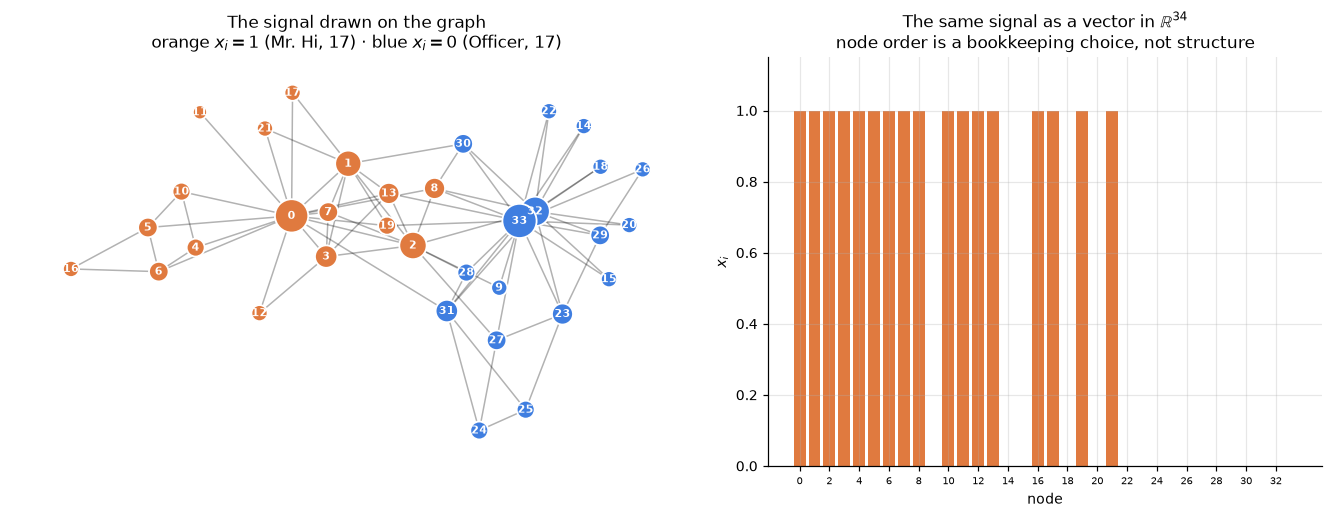

In [4]:
# Node coordinates for drawing. A spring layout is a VISUALISATION CHOICE -- the graph has no
# geometry of its own, so never read distance or angle in these pictures as meaningful.
# Every claim in this notebook is computed from matrices, not measured off a plot.
pos = nx.spring_layout(G, seed=SEED, weight=None)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), width_ratios=[1.25, 1])

nx.draw_networkx_edges(G, pos, ax=axes[0], alpha=0.3, width=1.0)
nx.draw_networkx_nodes(G, pos, ax=axes[0], nodelist=nodelist,
                       node_color=[C_HI if x[i] else C_OFF for i in range(N)],
                       node_size=[60 + 26 * d[i] for i in range(N)],
                       edgecolors="white", linewidths=1.2)
nx.draw_networkx_labels(G, pos, ax=axes[0], font_size=7.5, font_color="white", font_weight="bold")
axes[0].set_title("The signal drawn on the graph\n"
                  f"orange $x_i=1$ (Mr. Hi, {int(x.sum())}) $\cdot$ "
                  f"blue $x_i=0$ (Officer, {int(N - x.sum())})")
axes[0].set_axis_off()
axes[0].grid(False)

axes[1].bar(range(N), x, color=[C_HI if x[i] else C_OFF for i in range(N)])
axes[1].set_xticks(range(0, N, 2))
axes[1].set_xticklabels([nodelist[i] for i in range(0, N, 2)], fontsize=6.5)
axes[1].set_xlabel("node")
axes[1].set_ylabel("$x_i$")
axes[1].set_ylim(0, 1.15)
axes[1].set_title("The same signal as a vector in $\\mathbb{R}^{34}$\n"
                  "node order is a bookkeeping choice, not structure")
plt.show()

The right-hand panel is the honest picture of what a computer has: 34 numbers in a row. It looks
like noise because the node ordering carries no meaning — node 14 and node 15 are adjacent in the
array but need not be adjacent in the club. The left panel shows the same 34 numbers arranged by
the graph, and the structure becomes obvious.

Bridging those two pictures is exactly what the GFT does. It replaces an arbitrary ordering with a
basis the graph itself supplies.

> 📖 **Reference — the dataset.**
> [`networkx.karate_club_graph()` documentation](https://networkx.org/documentation/stable/reference/generated/networkx.generators.social.karate_club_graph.html).
> Read it for what nodes and edges record and for the citation to Zachary (1977). The `club`
> attribute we are using as the signal is the faction each member joined after the split; the
> integer edge weights are interaction counts, which we deliberately discard with `weight=None`.


---
## 2. Deriving and computing the GFT

### The basis, recalled

The combinatorial Laplacian is $L = D - A$, where $A$ is the adjacency matrix and
$D=\operatorname{diag}(d_1,\dots,d_N)$ holds the degrees. $L$ is real and symmetric, so the spectral
theorem gives

$$L \;=\; U \Lambda U^\top, \qquad U^\top U = U U^\top = I, \qquad 0=\lambda_1 \le \lambda_2 \le \cdots \le \lambda_N,$$

with $U = [\,u_1\;u_2\;\cdots\;u_N\,] \in \mathbb{R}^{N\times N}$ holding the orthonormal
eigenvectors as columns and $\Lambda = \operatorname{diag}(\lambda_1,\dots,\lambda_N)$ the
eigenvalues in ascending order.

Lesson 1 established what the ordering means. For any vector $q$,

$$q^\top L q \;=\; \sum_{\{i,j\}\in E} (q_i-q_j)^2 ,$$

the **Dirichlet energy** — how much $q$ disagrees across edges — and for a unit eigenvector this
collapses to $u_k^\top L u_k = \lambda_k$. So $\lambda_k$ *is* the Dirichlet energy of $u_k$: small
$\lambda_k$ means $u_k$ varies gently across edges, large $\lambda_k$ means it flips sharply. That is
the sense in which $\lambda_k$ is a **graph frequency**.

We use `numpy.linalg.eigh` — the `h` is for Hermitian (symmetric, in the real case). It exploits the
symmetry to return real eigenvalues, already ascending, with numerically orthonormal eigenvectors.
The general-purpose `numpy.linalg.eig` would ignore the symmetry and can return complex values with
spurious imaginary parts.

> **Indexing.** The mathematics is 1-based ($\lambda_1$ is the smallest); NumPy is 0-based
> (`lam[0]` is the smallest). So $u_2$, the Fiedler vector, is `U[:, 1]`. We keep mathematical names
> in prose and NumPy indices in code.


In [5]:
lam, U = np.linalg.eigh(L)        # eigh: symmetric solver, eigenvalues ascending

# eigh already sorts ascending; we make the ordering explicit rather than assumed.
order = np.argsort(lam)
lam, U = lam[order], U[:, order]

print(f"lambda_1  = {lam[0]:.3e}   (zero up to floating point; the graph is connected)")
print(f"lambda_2  = {lam[1]:.6f}   (algebraic connectivity)")
print(f"lambda_34 = {lam[-1]:.6f}")
print()
print(f"orthonormal, max |U^T U - I| = {np.abs(U.T @ U - np.eye(N)).max():.2e}")
print(f"eigenpair residual, max |L u_k - lambda_k u_k| = "
      f"{max(np.abs(L @ U[:, k] - lam[k] * U[:, k]).max() for k in range(N)):.2e}")

lambda_1  = 2.489e-16   (zero up to floating point; the graph is connected)
lambda_2  = 0.468525   (algebraic connectivity)
lambda_34 = 18.136696

orthonormal, max |U^T U - I| = 1.89e-15
eigenpair residual, max |L u_k - lambda_k u_k| = 1.60e-14


### Projection, coefficients, reconstruction

Because $U$ is an orthonormal basis of $\mathbb{R}^N$, *any* vector can be written in it — including
our measurement. The **graph Fourier transform** of $x$ is the vector of its coordinates in that
basis:

$$\widehat{x}_k \;=\; u_k^\top x \;=\; \sum_{i=1}^{N} u_k(i)\, x_i, \qquad\qquad \widehat{x} \;=\; U^\top x \;\in\; \mathbb{R}^N,$$

and the **inverse GFT** puts the pieces back together:

$$x \;=\; U\widehat{x} \;=\; \sum_{k=1}^{N} \widehat{x}_k\, u_k .$$

Every symbol: $u_k(i)$ is entry $i$ of eigenvector $u_k$; $\widehat{x}_k$ is a single real number,
the amount of pattern $u_k$ present in $x$; $\widehat{x}$ is the whole vector of them. The inverse is
exact, not an approximation — it holds because $UU^\top = I$.

Geometrically, $\widehat{x}_k u_k$ is the **orthogonal projection** of $x$ onto the line spanned by
$u_k$, and the sum of all $N$ projections rebuilds $x$ exactly.

Let us compute one coefficient by hand before using any matrix shortcut.


In [6]:
# --- ONE coefficient, computed explicitly as a sum over nodes ------------------
k = 2                                   # mathematical index: the Fiedler mode
u_k = U[:, k - 1]                       # NumPy index k-1

running = 0.0
print(f"xhat_{k} = u_{k}^T x = sum over the {N} nodes of u_{k}(i) * x_i")
print(f"{'i':>3s} {'node':>5s} {'u_' + str(k) + '(i)':>10s} {'x_i':>5s} {'product':>10s} {'running':>10s}")
for i in range(N):
    term = u_k[i] * x[i]
    running += term
    if i < 6 or i > N - 4:              # print the first few and the last few rows
        print(f"{i:3d} {nodelist[i]:5d} {u_k[i]:10.5f} {x[i]:5.0f} {term:10.5f} {running:10.5f}")
    elif i == 6:
        print(f"{'...':>3s} {'...':>5s} {'...':>10s} {'...':>5s} {'...':>10s} {'...':>10s}")

print()
print(f"explicit sum over nodes : {running:.10f}")
print(f"vector form  u_2 @ x    : {u_k @ x:.10f}")
print(f"matrix form  (U.T @ x)  : {(U.T @ x)[k - 1]:.10f}")
print(f"all three agree         : {np.isclose(running, u_k @ x) and np.isclose(running, (U.T @ x)[k - 1])}")

xhat_2 = u_2^T x = sum over the 34 nodes of u_2(i) * x_i
  i  node     u_2(i)   x_i    product    running
  0     0   -0.11214     1   -0.11214   -0.11214
  1     1   -0.04129     1   -0.04129   -0.15343
  2     2    0.02322     1    0.02322   -0.13021
  3     3   -0.05550     1   -0.05550   -0.18571
  4     4   -0.28460     1   -0.28460   -0.47031
  5     5   -0.32373     1   -0.32373   -0.79404
...   ...        ...   ...        ...        ...
 31    31    0.09875     0    0.00000   -2.37532
 32    32    0.13035     0    0.00000   -2.37532
 33    33    0.11890     0    0.00000   -2.37532

explicit sum over nodes : -2.3753158896
vector form  u_2 @ x    : -2.3753158896
matrix form  (U.T @ x)  : -2.3753158896
all three agree         : True


Only the $x_i = 1$ nodes contribute: a coefficient is a *weighted vote*, in which every member of
Mr. Hi's faction casts a vote of size $u_2(i)$ and everyone else abstains. Since $u_2$ is negative
across most of that faction, the total comes out strongly negative. The sign carries no absolute
meaning — $-u_2$ is an equally valid eigenvector, which would flip $\widehat{x}_2$ — but the
*magnitude* says this pattern is strongly present.

Now look at what that one coefficient contributes: the projection $\widehat{x}_k u_k$, a vector in
$\mathbb{R}^N$ that we can draw on the graph just like the signal itself.


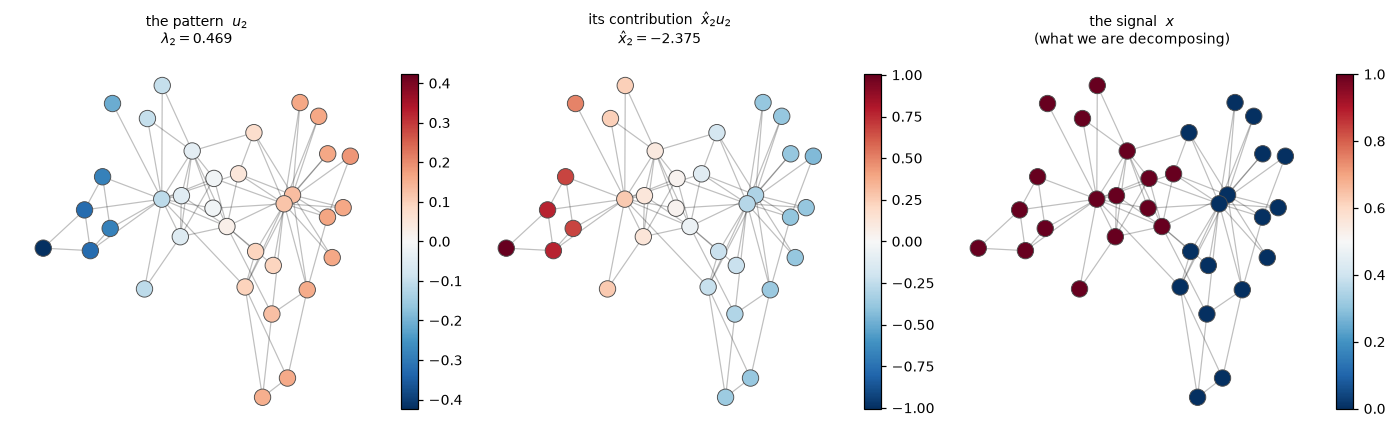

xhat_2         = -2.375316
||xhat_2 u_2|| = 2.375316   (since ||u_2|| = 1, the length IS |xhat_2|)
this one mode already accounts for 33.2% of ||x||^2


In [7]:
def draw_on_graph(ax, vec, title, vmin=None, vmax=None, cmap="RdBu_r", centre=None):
    # Colour nodes by the entries of vec. If centre is given, the colour scale is made
    # symmetric about it so that "centre" reads as white.
    if vmin is None or vmax is None:
        c = 0.0 if centre is None else centre
        m = np.abs(vec - c).max()
        vmin, vmax = c - m, c + m
    nx.draw_networkx_edges(G, pos, ax=ax, alpha=0.25, width=0.8)
    nodes = nx.draw_networkx_nodes(G, pos, ax=ax, nodelist=nodelist, node_color=vec,
                                   cmap=cmap, vmin=vmin, vmax=vmax, node_size=115,
                                   edgecolors="0.3", linewidths=0.6)
    ax.set_title(title, fontsize=9)
    ax.set_axis_off()
    ax.grid(False)
    return nodes


xhat_2 = U[:, 1] @ x

fig, axes = plt.subplots(1, 3, figsize=(12.6, 3.9))
for ax, (vec, title) in zip(axes, [
        (U[:, 1], f"the pattern  $u_2$\n$\\lambda_2 = {lam[1]:.3f}$"),
        (xhat_2 * U[:, 1], f"its contribution  $\\hat{{x}}_2 u_2$\n$\\hat{{x}}_2 = {xhat_2:.3f}$"),
        (x, "the signal  $x$\n(what we are decomposing)")]):
    nodes = draw_on_graph(ax, vec, title, centre=0.5 if title.startswith("the signal") else 0.0)
    fig.colorbar(nodes, ax=ax, fraction=0.045)
plt.show()

print(f"xhat_2         = {xhat_2:.6f}")
print(f"||xhat_2 u_2|| = {np.abs(xhat_2):.6f}   (since ||u_2|| = 1, the length IS |xhat_2|)")
print(f"this one mode already accounts for "
      f"{100 * xhat_2 ** 2 / (x @ x):.1f}% of ||x||^2")

The middle panel is a rescaled copy of the left panel — that is all a single coefficient can ever
produce. Comparing it with the right panel shows both the promise and the limit: $u_2$ captures the
two-faction structure, but it is smooth where the true signal is a hard step, and it is centred on
zero where the true signal sits between 0 and 1. The missing piece is the constant mode, which
Section 3 takes up.

### All the coefficients at once

Every coefficient is a projection onto one eigenvector, so the whole transform is one matrix
product. We now define the convenience functions, having seen the sum they stand for.


In [8]:
def gft(signal):
    # Graph Fourier transform: coefficients of `signal` in the eigenbasis U.
    return U.T @ signal

def igft(coeffs):
    # Inverse graph Fourier transform: rebuild a signal from its coefficients.
    return U @ coeffs

xhat = gft(x)

print(f"xhat shape: {xhat.shape}   (one real number per graph frequency)")
print(f"inversion exact: max |igft(gft(x)) - x| = {np.abs(igft(gft(x)) - x).max():.2e}")
print()
print(f"{'k':>3s} {'lambda_k':>10s} {'xhat_k':>10s} {'|xhat_k|^2':>11s} {'% of ||x||^2':>13s}")
for k in np.argsort(-np.abs(xhat))[:6]:
    print(f"{k + 1:3d} {lam[k]:10.4f} {xhat[k]:+10.4f} {xhat[k] ** 2:11.4f} "
          f"{100 * xhat[k] ** 2 / (x @ x):12.1f}%")
print(f"\n(rows sorted by |xhat_k|, not by k -- the six modes carrying the most of this signal)")

xhat shape: (34,)   (one real number per graph frequency)
inversion exact: max |igft(gft(x)) - x| = 2.44e-15

  k   lambda_k     xhat_k  |xhat_k|^2  % of ||x||^2
  1     0.0000    +2.9155      8.5000         50.0%
  2     0.4685    -2.3753      5.6421         33.2%
  4     1.1250    -0.9717      0.9443          5.6%
  3     0.9092    +0.7753      0.6011          3.5%
 25     5.3786    -0.7138      0.5096          3.0%
 16     2.7492    -0.4704      0.2213          1.3%

(rows sorted by |xhat_k|, not by k -- the six modes carrying the most of this signal)


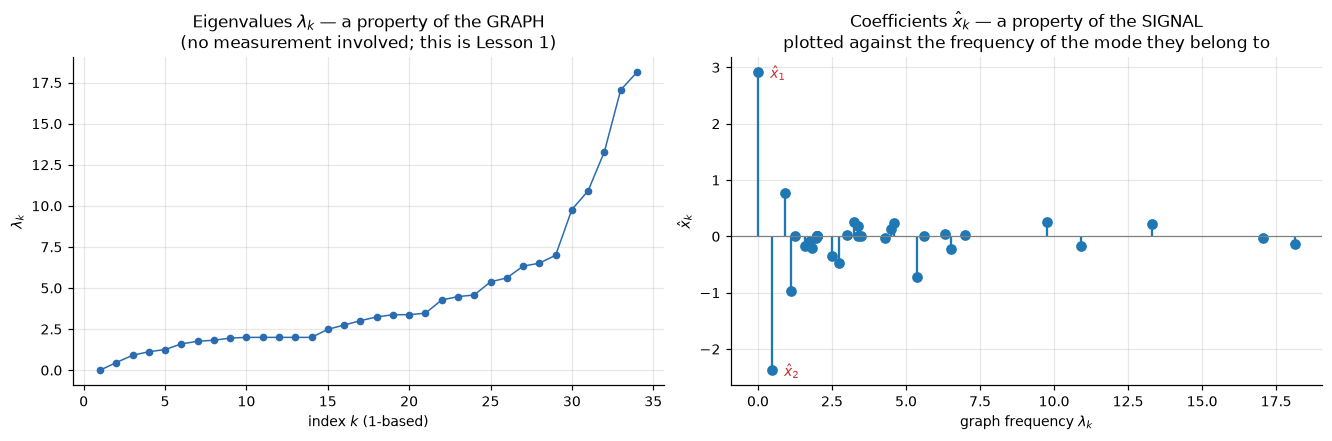

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.9))

# Left: the spectrum -- a property of the GRAPH alone.
axes[0].plot(np.arange(1, N + 1), lam, "o-", ms=4, lw=1, color=C_LINE)
axes[0].set_xlabel("index $k$ (1-based)")
axes[0].set_ylabel(r"$\lambda_k$")
axes[0].set_title("Eigenvalues $\\lambda_k$ — a property of the GRAPH\n"
                  "(no measurement involved; this is Lesson 1)")

# Right: the coefficients -- a property of the SIGNAL on that graph.
axes[1].stem(lam, xhat, basefmt=" ")
axes[1].axhline(0, color="gray", lw=0.8)
axes[1].set_xlabel(r"graph frequency $\lambda_k$")
axes[1].set_ylabel(r"$\hat{x}_k$")
axes[1].set_title("Coefficients $\\hat{x}_k$ — a property of the SIGNAL\n"
                  "plotted against the frequency of the mode they belong to")
for k in [0, 1]:
    axes[1].annotate(f"$\\hat{{x}}_{{{k + 1}}}$", (lam[k], xhat[k]),
                     textcoords="offset points", xytext=(8, -4), color=C_RED, fontsize=9)
plt.show()

> ⚠️ **Two different objects, easily conflated.** The left panel has $k$ on the horizontal axis and
> plots $\lambda_k$; it would look identical if we had measured nothing at all. The right panel has
> $\lambda_k$ on the horizontal axis and plots $\widehat{x}_k$; it changes completely if we measure
> something else on the same graph. $\lambda_k$ describes a *pattern*, $\widehat{x}_k$ describes *our
> data's overlap with that pattern*. Plotting coefficients against eigenvalues, as on the right, is
> the standard presentation precisely because it puts the data on a frequency axis the graph
> defines.

### "Frequency" here means variation across edges, not time

Nothing in this lesson is a time series. The horizontal axis on the right is $\lambda_k$, which
Lesson 1 established as the Dirichlet energy of $u_k$ — how much that pattern disagrees across
edges. Low graph frequency means *neighbours hold similar values*. It does not mean slow, and it has
no period, no sampling rate, and no cycles per second.

A tempting shortcut is to line the 34 values up in node order and run an ordinary FFT. That is not
a graph transform, and the reason is worth demonstrating rather than asserting: the FFT assumes its
samples lie on a **path** — sample $i$ adjacent to $i\pm1$ — and our node ordering is arbitrary
bookkeeping. Relabelling the nodes changes nothing about the club, so a legitimate transform must
be insensitive to it.


In [10]:
# Relabel the nodes at random. Same club, same relationships -- only the names change.
perm = rng.permutation(N)
G_relab = nx.relabel_nodes(G, {nodelist[i]: int(perm[i]) for i in range(N)})
nodelist_relab = sorted(G_relab.nodes())

A_relab = nx.to_numpy_array(G_relab, nodelist=nodelist_relab, weight=None)
lam_relab, U_relab = np.linalg.eigh(np.diag(A_relab.sum(axis=1)) - A_relab)

x_relab = np.empty(N)
x_relab[perm] = x                       # carry each member's own value to their new label

# Compare magnitudes: the GLOBAL SIGN of an eigenvector is arbitrary (Lesson 1), so
# |coefficient| is the quantity that can be meaningfully compared between the two runs.
gft_diff = np.abs(np.abs(U_relab.T @ x_relab) - np.abs(xhat)).max()
fft_diff = np.abs(np.abs(np.fft.rfft(x_relab)) - np.abs(np.fft.rfft(x))).max()

print(f"spectrum unchanged by relabelling : {np.allclose(lam, lam_relab)}")
print()
print(f"GFT: max change in |coefficients| = {gft_diff:.2e}   <- invariant, as it must be")
print(f"FFT: max change in |coefficients| = {fft_diff:.4f}     <- completely different answer")
print()
print("The FFT result depends on an ordering that carries no information about the club.")
print("The GFT result depends only on who is connected to whom.")

spectrum unchanged by relabelling : True

GFT: max change in |coefficients| = 1.69e-14   <- invariant, as it must be
FFT: max change in |coefficients| = 4.5379     <- completely different answer

The FFT result depends on an ordering that carries no information about the club.
The GFT result depends only on who is connected to whom.


The GFT magnitudes are unchanged to machine precision; the FFT magnitudes are unrecognisable. An
FFT on graph data does not merely lose information — it **invents** a neighbourhood structure
(node $i$ next to node $i+1$) that the data never had, and then reports properties of that
invention.

> 📖 **Reference — the GFT and graph frequency.**
> [Shuman, Narang, Frossard, Ortega & Vandergheynst, *The Emerging Field of Signal Processing on
> Graphs* (2013)](https://arxiv.org/abs/1211.0053). Sections II–III define the GFT exactly as above
> and develop the frequency interpretation, including the zero-crossing argument for calling
> $\lambda_k$ a frequency. This paper is the primary foundation for everything in this notebook.


---
## 3. Mean, energy, and smoothness

### The constant mode carries the mean

For a connected graph the smallest eigenvalue is $\lambda_1=0$ and its eigenvector is constant.
Normalised to unit length,

$$u_1 \;=\; \frac{1}{\sqrt{N}}\,\mathbf{1} \;=\; \frac{1}{\sqrt{N}}(1,1,\dots,1)^\top ,$$

so the first coefficient is the mean in disguise:

$$\widehat{x}_1 \;=\; u_1^\top x \;=\; \frac{1}{\sqrt{N}}\sum_{i=1}^{N} x_i \;=\; \sqrt{N}\,\bar{x} .$$

This one mode is not about network structure at all — it is the overall level. Because it is the
single largest coefficient for most real signals, it will dominate any energy plot and hide
everything else, which is why the centred spectrum below is the more informative picture.


In [11]:
print(f"u_1 constant?        {np.allclose(U[:, 0], U[0, 0])}")
print(f"u_1 entries          all equal to {U[0, 0]:.6f}")
print(f"1/sqrt(N)            {1 / np.sqrt(N):.6f}   (up to the arbitrary global sign)")
print()
print(f"xhat_1               {xhat[0]:.6f}")
print(f"sqrt(N) * xbar       {np.sqrt(N) * x.mean():.6f}")
print(f"agree                {np.isclose(abs(xhat[0]), np.sqrt(N) * x.mean())}")
print()
print(f"xhat_1^2 as a share of ||x||^2 : {100 * xhat[0] ** 2 / (x @ x):.1f}%")
print("-> half the energy of this signal is just 'the mean is 0.5'.")

# The mean-centred signal: same structure, constant mode removed.
x_centred = x - x.mean()
xhat_centred = gft(x_centred)
print()
print(f"after centring, xhat_1 = {xhat_centred[0]:.2e}  (zero, as it must be)")
print(f"the other coefficients are unchanged: "
      f"{np.allclose(xhat_centred[1:], xhat[1:])}")

u_1 constant?        True
u_1 entries          all equal to 0.171499
1/sqrt(N)            0.171499   (up to the arbitrary global sign)

xhat_1               2.915476
sqrt(N) * xbar       2.915476
agree                True

xhat_1^2 as a share of ||x||^2 : 50.0%
-> half the energy of this signal is just 'the mean is 0.5'.

after centring, xhat_1 = 5.72e-15  (zero, as it must be)
the other coefficients are unchanged: True


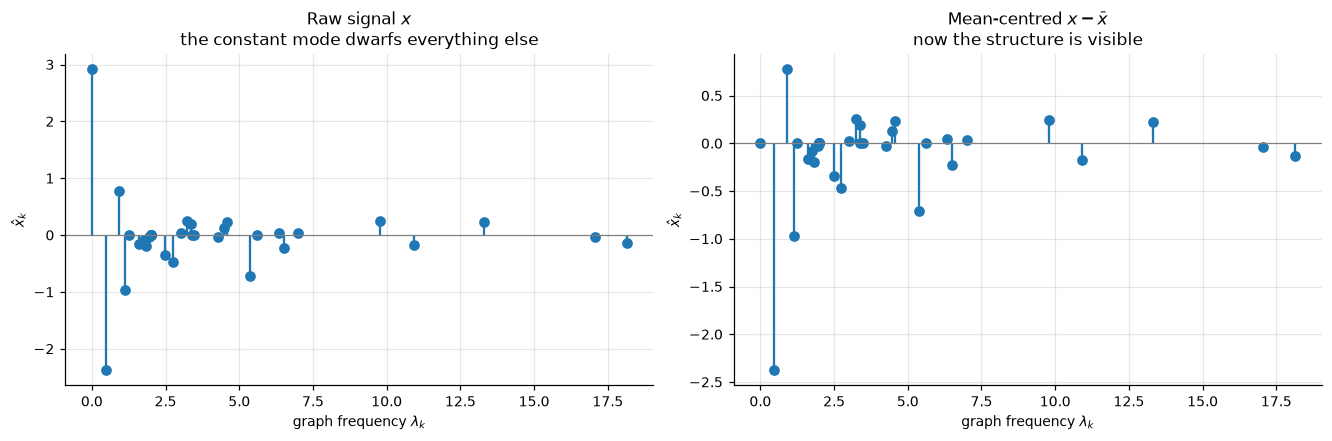

share of NON-CONSTANT energy in the single Fiedler mode u_2 : 66.4%
share in the two smoothest non-constant modes u_2, u_3      : 73.4%


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.9), sharey=False)

axes[0].stem(lam, xhat, basefmt=" ")
axes[0].set_title("Raw signal $x$\nthe constant mode dwarfs everything else")
axes[1].stem(lam, xhat_centred, basefmt=" ")
axes[1].set_title("Mean-centred $x - \\bar{x}$\nnow the structure is visible")
for ax in axes:
    ax.axhline(0, color="gray", lw=0.8)
    ax.set_xlabel(r"graph frequency $\lambda_k$")
    ax.set_ylabel(r"$\hat{x}_k$")
plt.show()

share = xhat_centred[1] ** 2 / (xhat_centred @ xhat_centred)
print(f"share of NON-CONSTANT energy in the single Fiedler mode u_2 : {share:.1%}")
print(f"share in the two smoothest non-constant modes u_2, u_3      : "
      f"{(xhat_centred[1:3] ** 2).sum() / (xhat_centred @ xhat_centred):.1%}")

Two-thirds of the non-constant energy sits in $u_2$ alone — the very pattern Lesson 1 used to
predict the split. The membership signal and the graph's principal bottleneck are largely the same
object, now measured rather than asserted.

### Two conservation laws

**Parseval's identity.** Because $U$ is orthonormal, the transform preserves length:

$$\|x\|_2^2 \;=\; x^\top x \;=\; x^\top U U^\top x \;=\; \|\widehat{x}\|_2^2 \;=\; \sum_{k=1}^{N} |\widehat{x}_k|^2 .$$

Energy is neither created nor destroyed by the change of basis — only redistributed across
frequencies. This is what licenses reading $|\widehat{x}_k|^2$ as "the amount of the signal at
frequency $\lambda_k$".

**Dirichlet energy, in two forms.** Lesson 1 gave the edge form. Substituting $x = U\widehat{x}$ and
using $L = U\Lambda U^\top$ gives the spectral form:

$$x^\top L x \;=\; \underbrace{\sum_{\{i,j\}\in E}(x_i-x_j)^2}_{\text{Lesson 1: sum over edges}} \;=\; \underbrace{\sum_{k=1}^{N}\lambda_k\,|\widehat{x}_k|^2}_{\text{this lesson: sum over frequencies}} .$$

One number, two readings. The edge form says *how much neighbours disagree*; the spectral form says
*which frequencies that disagreement is made of*, weighting each mode's energy by its own frequency.
The constant mode contributes nothing, since $\lambda_1 = 0$ — consistent with the edge form, where
adding a constant to every node changes no difference.

**For a 0/1 signal the Dirichlet energy has an exact combinatorial meaning.** If $x_i,x_j\in\{0,1\}$
then $(x_i-x_j)^2$ is $1$ when the edge joins the two factions and $0$ otherwise, so

$$x^\top L x \;=\; \#\{\text{edges crossing between the clubs}\} .$$

That is a rare and useful thing: a spectral quantity that is literally a count.


In [13]:
# --- Parseval --------------------------------------------------------------
print("Parseval's identity")
print(f"  ||x||^2            = {x @ x:.10f}")
print(f"  sum_k |xhat_k|^2   = {(xhat ** 2).sum():.10f}")
print(f"  agree              = {np.isclose(x @ x, (xhat ** 2).sum())}")
print()

# --- Dirichlet energy, three ways ------------------------------------------
def dirichlet_edges(signal):
    # Sum over edges of (x_i - x_j)^2 -- the Lesson 1 form, straight from the edge list.
    return sum((signal[i] - signal[j]) ** 2 for i, j in edge_idx)

cut_edges = [(nodelist[i], nodelist[j]) for i, j in edge_idx if x[i] != x[j]]

print("Dirichlet energy")
print(f"  matrix form    x^T L x              = {x @ L @ x:.10f}")
print(f"  edge form      sum_E (x_i - x_j)^2  = {dirichlet_edges(x):.10f}")
print(f"  spectral form  sum_k lam_k |xhat|^2 = {(lam * xhat ** 2).sum():.10f}")
print()
print(f"  edges crossing between the clubs    = {len(cut_edges)} of {G.number_of_edges()}")
print(f"  -> for a 0/1 signal the energy IS that count: {np.isclose(x @ L @ x, len(cut_edges))}")
print(f"  the crossing edges: {cut_edges}")
print()

# --- and the scale-free version -------------------------------------------
def rayleigh(signal):
    # Dirichlet energy per unit squared length -- comparable between signals.
    return (signal @ L @ signal) / (signal @ signal)

print(f"Rayleigh quotient R(x)         = {rayleigh(x):.6f}")
print(f"R(x) is unchanged by rescaling : {np.isclose(rayleigh(x), rayleigh(100 * x))}")
print(f"R(x) IS changed by centring    : R(x - xbar) = {rayleigh(x_centred):.6f}")
print("  (centring removes ||x||^2 but not the energy, so the ratio moves -- state which you use)")

Parseval's identity
  ||x||^2            = 17.0000000000
  sum_k |xhat_k|^2   = 17.0000000000
  agree              = True

Dirichlet energy
  matrix form    x^T L x              = 11.0000000000
  edge form      sum_E (x_i - x_j)^2  = 11.0000000000
  spectral form  sum_k lam_k |xhat|^2 = 11.0000000000

  edges crossing between the clubs    = 11 of 78
  -> for a 0/1 signal the energy IS that count: True
  the crossing edges: [(0, 31), (1, 30), (2, 9), (2, 27), (2, 28), (2, 32), (8, 30), (8, 32), (8, 33), (13, 33), (19, 33)]

Rayleigh quotient R(x)         = 0.647059
R(x) is unchanged by rescaling : True
R(x) IS changed by centring    : R(x - xbar) = 1.294118
  (centring removes ||x||^2 but not the energy, so the ratio moves -- state which you use)


### Is 11 a small number of crossing edges?

Following the habit from Lesson 1: a quantity with no yardstick is not yet a finding. Eleven
crossing edges sounds few, but few *compared to what*?

Here the right null model is the mirror image of Lesson 1's. There we held the signal absent and
rewired the graph. Now we **hold the graph fixed and shuffle the signal across its nodes** — keeping
17 ones and 17 zeros, but assigning them to members at random. That ensemble answers exactly the
question the section opened with: *is membership aligned with network structure, or would any
17/17 split of these members look like this?*

The expected number of crossing edges under that null has a closed form. For a uniformly random
assignment of $N_1$ ones among $N$ nodes, each edge crosses with probability
$2\,\frac{N_1}{N}\cdot\frac{N-N_1}{N-1}$, so

$$\mathbb{E}[\text{crossing edges}] \;=\; |E| \cdot \frac{2N_1(N-N_1)}{N(N-1)} .$$

We check the simulation against that formula — a cheap way to catch a broken null.


In [14]:
N_NULL = 5000
null_energy = np.empty(N_NULL)

# Shuffle the SAME 17 ones and 17 zeros across the nodes; the graph is untouched.
for s in range(N_NULL):
    x_shuffled = rng.permutation(x)
    null_energy[s] = x_shuffled @ L @ x_shuffled

N1 = int(x.sum())
expected = G.number_of_edges() * 2 * N1 * (N - N1) / (N * (N - 1))

print(f"observed crossing edges                 : {x @ L @ x:.0f}")
print(f"null mean over {N_NULL} shuffles          : {null_energy.mean():.2f}")
print(f"analytic expectation |E|*2*N1*(N-N1)/... : {expected:.2f}")
print(f"simulation matches the formula          : {abs(null_energy.mean() - expected) < 0.5}")
print()
print(f"null minimum across all {N_NULL} shuffles  : {null_energy.min():.0f}")
print(f"shuffles at least as smooth as observed : "
      f"{np.mean(null_energy <= x @ L @ x):.2%}")

observed crossing edges                 : 11
null mean over 5000 shuffles          : 40.24
analytic expectation |E|*2*N1*(N-N1)/... : 40.18
simulation matches the formula          : True

null minimum across all 5000 shuffles  : 23
shuffles at least as smooth as observed : 0.00%


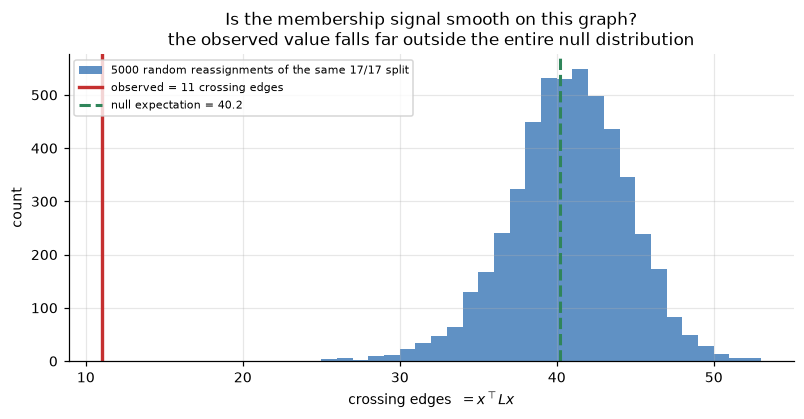

In [15]:
fig, ax = plt.subplots(figsize=(7.2, 3.7))
ax.hist(null_energy, bins=30, color=C_LINE, alpha=0.75,
        label=f"{N_NULL} random reassignments of the same 17/17 split")
ax.axvline(x @ L @ x, color=C_RED, lw=2.2, label=f"observed = {x @ L @ x:.0f} crossing edges")
ax.axvline(expected, color=C_GREEN, lw=2.0, ls="--", label=f"null expectation = {expected:.1f}")
ax.set_xlabel("crossing edges  $=x^\\top L x$")
ax.set_ylabel("count")
ax.set_title("Is the membership signal smooth on this graph?\n"
             "the observed value falls far outside the entire null distribution")
ax.legend(fontsize=7.5)
plt.show()

The observed value is not merely in the tail — it is below the **minimum of 5000 shuffles**. The
faction a member joined is about as strongly aligned with their interaction network as this data
could express. That is the quantitative answer to the question in Section 1.

> ⚠️ **What this null does and does not randomise.** It keeps the graph, and it keeps the number of
> ones, changing only *which members* hold them. So it isolates alignment between signal and
> structure. It does not test whether the graph itself is unusual — Lesson 1's degree-preserving
> rewiring null does that — and it does not establish causation. People plausibly joined the faction
> their friends joined, but the same statistic would arise if pre-existing factions determined who
> socialised with whom. A smoothness test cannot separate those stories; it only reports that
> signal and structure agree.

### Where the energy sits

Two standard plots. **Spectral energy** $|\widehat{x}_k|^2$ against $\lambda_k$ shows which
frequencies carry the signal; **cumulative energy** shows how quickly the total accumulates as modes
are added, which is what Section 4 exploits.


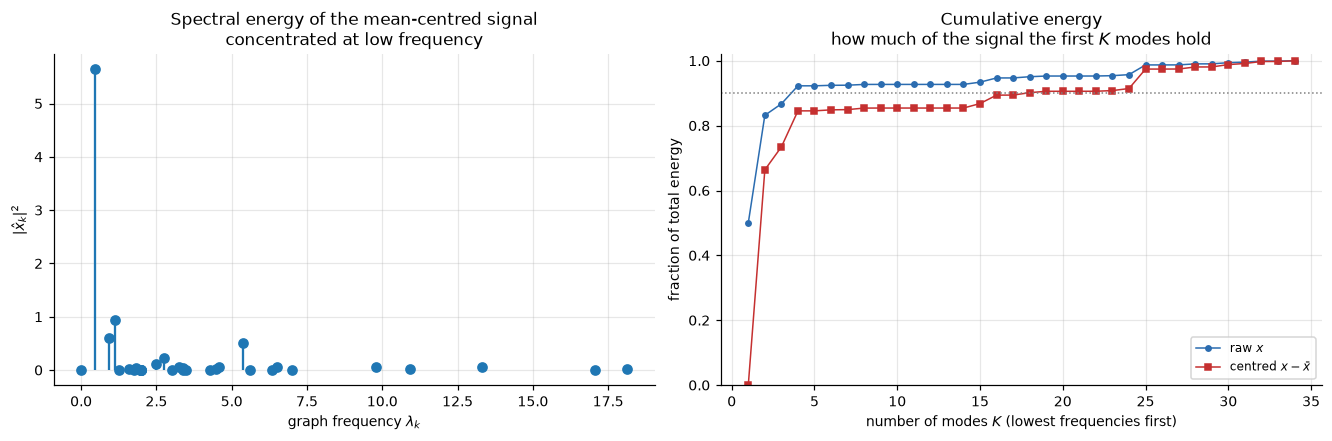

  first  1 modes hold  50.0% of ||x||^2   (  0.0% of the centred signal's energy)
  first  2 modes hold  83.2% of ||x||^2   ( 66.4% of the centred signal's energy)
  first  3 modes hold  86.7% of ||x||^2   ( 73.4% of the centred signal's energy)
  first  5 modes hold  92.3% of ||x||^2   ( 84.6% of the centred signal's energy)
  first 10 modes hold  92.7% of ||x||^2   ( 85.4% of the centred signal's energy)


In [16]:
energy = xhat ** 2
energy_c = xhat_centred ** 2
cumulative = np.cumsum(energy) / energy.sum()
cumulative_c = np.cumsum(energy_c) / energy_c.sum()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.9))

axes[0].stem(lam, energy_c, basefmt=" ")
axes[0].set_xlabel(r"graph frequency $\lambda_k$")
axes[0].set_ylabel(r"$|\hat{x}_k|^2$")
axes[0].set_title("Spectral energy of the mean-centred signal\nconcentrated at low frequency")

axes[1].plot(np.arange(1, N + 1), cumulative, "o-", ms=3.5, lw=1, color=C_LINE,
             label="raw $x$")
axes[1].plot(np.arange(1, N + 1), cumulative_c, "s-", ms=3.5, lw=1, color=C_RED,
             label=r"centred $x-\bar{x}$")
axes[1].axhline(0.9, color="gray", ls=":", lw=1)
axes[1].set_xlabel("number of modes $K$ (lowest frequencies first)")
axes[1].set_ylabel("fraction of total energy")
axes[1].set_title("Cumulative energy\nhow much of the signal the first $K$ modes hold")
axes[1].legend(fontsize=8)
axes[1].set_ylim(0, 1.02)
plt.show()

for K in [1, 2, 3, 5, 10]:
    print(f"  first {K:2d} modes hold {cumulative[K - 1]:6.1%} of ||x||^2   "
          f"({cumulative_c[K - 1]:6.1%} of the centred signal's energy)")

The centred curve rises steeply and then flattens: most of the structure is in a handful of low
frequencies, but the last few percent is spread thinly over many high-frequency modes. That tail is
the hard part — it encodes the fact that the true signal is a **step function**, exactly 0 or
exactly 1, and steps are expensive to build from smooth pieces. Section 4 is about paying or not
paying for that tail.


---
## 4. Approximation and compression

Keeping only the $K$ lowest frequencies gives the **truncated reconstruction**

$$x^{(K)} \;=\; \sum_{k=1}^{K} \widehat{x}_k\, u_k \;=\; U_{:,1:K}\,\widehat{x}_{1:K},$$

and because the basis is orthonormal, the error is exactly the energy of what we discarded:

$$\bigl\|x - x^{(K)}\bigr\|_2^2 \;=\; \sum_{k>K} |\widehat{x}_k|^2 .$$

No approximation in that statement — it is Parseval applied to the difference. So the cumulative
energy curve from Section 3 *is* the error curve, read upside down. We verify it rather than trust
it.


In [17]:
def reconstruct(coeffs, K):
    # Keep the K lowest-frequency coefficients, discard the rest, transform back.
    kept = np.zeros_like(coeffs)
    kept[:K] = coeffs[:K]
    return igft(kept)

print(f"{'K':>3s} {'||x - x^(K)||^2':>17s} {'sum_{k>K} |xhat_k|^2':>22s} {'match':>7s}")
for K in [1, 2, 3, 5, 10, 17, 34]:
    xk = reconstruct(xhat, K)
    lhs = np.linalg.norm(x - xk) ** 2
    rhs = (xhat[K:] ** 2).sum()
    print(f"{K:3d} {lhs:17.8f} {rhs:22.8f} {str(np.isclose(lhs, rhs)):>7s}")

  K   ||x - x^(K)||^2   sum_{k>K} |xhat_k|^2   match
  1        8.50000000             8.50000000    True
  2        2.85787442             2.85787442    True
  3        2.25682061             2.25682061    True
  5        1.31252143             1.31252143    True
 10        1.23856103             1.23856103    True
 17        0.89934972             0.89934972    True
 34        0.00000000             0.00000000    True


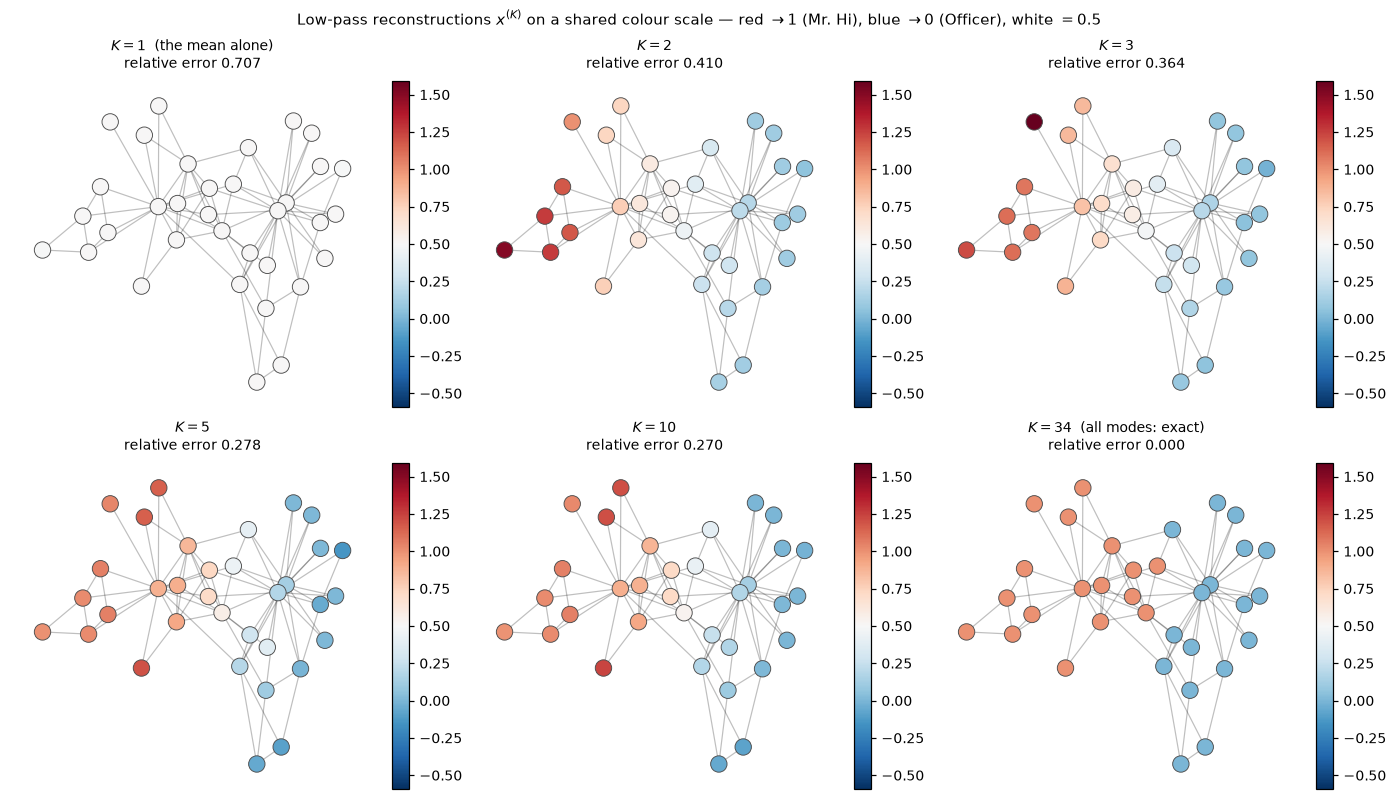

In [18]:
Ks = [1, 2, 3, 5, 10, 34]
recs = {K: reconstruct(xhat, K) for K in Ks}

# ONE colour scale for every panel, symmetric about 0.5 so that "undecided" reads white.
m = max(np.abs(np.concatenate([r for r in recs.values()]) - 0.5).max(),
        np.abs(x - 0.5).max())
VMIN, VMAX = 0.5 - m, 0.5 + m

fig, axes = plt.subplots(2, 3, figsize=(12.6, 7.2))
for ax, K in zip(axes.ravel(), Ks):
    rec = recs[K]
    rel = np.linalg.norm(x - rec) / np.linalg.norm(x)
    label = {1: "  (the mean alone)", 34: "  (all modes: exact)"}.get(K, "")
    nodes = draw_on_graph(ax, rec, f"$K = {K}${label}\nrelative error {rel:.3f}",
                          vmin=VMIN, vmax=VMAX)
    fig.colorbar(nodes, ax=ax, fraction=0.045)
fig.suptitle("Low-pass reconstructions $x^{(K)}$ on a shared colour scale — "
             "red $\\to 1$ (Mr. Hi), blue $\\to 0$ (Officer), white $= 0.5$", fontsize=10)
plt.show()

$K=1$ is the mean and nothing else: every node the same pale value, no structure at all. $K=2$ adds
the Fiedler mode and the two factions separate immediately. Beyond that the changes are
increasingly local — the reconstruction is sharpening individual members rather than discovering
groups — and only at $K=34$ do we recover the exact 0/1 step.

### How good is a truncated reconstruction, really?

Two comparisons, checking different things.

**Against the trivial baseline.** $K=1$ *is* the mean-only reconstruction, so the error curve
already contains it. Anything above that error is worse than not modelling the network at all.

**Against a different basis.** The real question is whether the *graph's* basis is a good place to
compress this signal. The natural competitor is the basis we started in: keep the $K$ largest raw
entries of $x$ and set the rest to zero. That is "compression in the node domain", and it costs $K$
numbers too, so the comparison is fair.


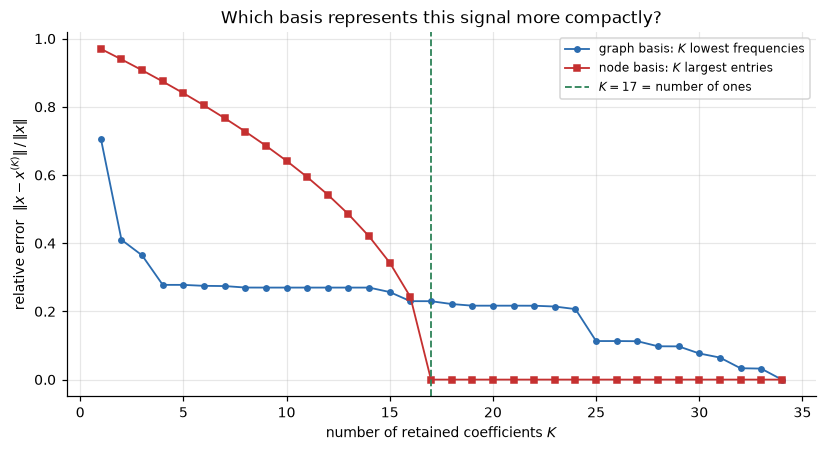

  K   graph basis   node basis   winner
  1        0.7071       0.9701   graph
  2        0.4100       0.9393   graph
  3        0.3644       0.9075   graph
  5        0.2779       0.8402   graph
 10        0.2699       0.6417   graph
 17        0.2300       0.0000   node
 20        0.2168       0.0000   node
 34        0.0000       0.0000   tie


In [19]:
def node_domain_truncation(signal, K):
    # Baseline: keep the K largest-magnitude ENTRIES of the signal, zero the rest.
    kept = np.zeros_like(signal)
    idx = np.argsort(-np.abs(signal))[:K]
    kept[idx] = signal[idx]
    return kept

Kgrid = np.arange(1, N + 1)
err_gft = np.array([np.linalg.norm(x - reconstruct(xhat, K)) / np.linalg.norm(x) for K in Kgrid])
err_node = np.array([np.linalg.norm(x - node_domain_truncation(x, K)) / np.linalg.norm(x)
                     for K in Kgrid])

fig, ax = plt.subplots(figsize=(7.4, 4.0))
ax.plot(Kgrid, err_gft, "o-", ms=3.5, lw=1.2, color=C_LINE,
        label="graph basis: $K$ lowest frequencies")
ax.plot(Kgrid, err_node, "s-", ms=3.5, lw=1.2, color=C_RED,
        label="node basis: $K$ largest entries")
ax.axvline(int(x.sum()), color=C_GREEN, ls="--", lw=1.2,
           label=f"$K = {int(x.sum())}$ = number of ones")
ax.set_xlabel("number of retained coefficients $K$")
ax.set_ylabel(r"relative error  $\|x - x^{(K)}\| \, / \, \|x\|$")
ax.set_title("Which basis represents this signal more compactly?")
ax.legend(fontsize=8)
plt.show()

print(f"{'K':>3s} {'graph basis':>13s} {'node basis':>12s}   winner")
for K in [1, 2, 3, 5, 10, 17, 20, 34]:
    g, nd = err_gft[K - 1], err_node[K - 1]
    print(f"{K:3d} {g:13.4f} {nd:12.4f}   {'graph' if g < nd - 1e-12 else 'node' if nd < g - 1e-12 else 'tie'}")

**The graph basis wins decisively for small $K$, and then loses outright at $K=17$.**

That crossover is not a defect, and it is worth understanding rather than hiding. Our signal has
exactly 17 non-zero entries, so it is *17-sparse in the node basis*: keeping the 17 largest entries
reproduces it perfectly, with zero error. The graph basis never achieves that until all 34 modes are
used, because a hard 0/1 step is not compactly expressible in smooth patterns.

So the honest summary is:

- If you want a **faithful few-number summary of the shape** — two numbers capturing "two factions,
  split roughly here" — the graph basis is dramatically better ($0.41$ versus $0.94$ relative error
  at $K=2$).
- If you want **exact reconstruction with as few numbers as possible**, and your signal happens to
  be sparse in the node domain, the node basis wins and the graph buys you nothing.

Which is the right goal depends on the application, and a basis is not "better" in the abstract.
What the graph basis genuinely provides here is that its *first few* coefficients are interpretable
— $\widehat{x}_2$ means "faction structure" — whereas the first few node-domain entries mean only
"some members of Mr. Hi's group, in an arbitrary order".

> ⚠️ **Three things a reconstruction is not.**
>
> **Not a probability.** $x^{(K)}_i = 0.73$ does not mean a 73% chance that member $i$ joined Mr. Hi.
> It is a continuous approximation to a binary value, with no calibration and no probabilistic model
> behind it. Values fall outside $[0,1]$ — check the colour bar — which a probability cannot do.
>
> **Not a prediction.** We reconstructed data we already had, using coefficients computed *from that
> same data*. Nothing was held out. This measures how compactly the graph represents a known signal,
> which is a statement about representation, not about generalisation. Predicting withheld node
> values is a genuinely different problem (graph sampling and recovery); it needs a held-out split
> and a baseline, and it is not what this section did.
>
> **Not a classifier, though it can be read as one.** Thresholding $x^{(K)}$ at $0.5$ recovers the
> factions well, as the next cell shows — but that reproduces Lesson 1's Fiedler partition rather
> than adding evidence, since at $K=2$ the threshold is doing exactly what the sign of $u_2$ did.


In [20]:
print("Thresholding the reconstruction at 0.5 (shown to make the previous point concrete):")
print(f"{'K':>3s} {'spread (max - min)':>20s} {'agreement with the split':>26s}")
for K in [1, 2, 3, 5, 10, 34]:
    rec = reconstruct(xhat, K)
    print(f"{K:3d} {np.ptp(rec):20.2e} {np.mean((rec > 0.5) == (x > 0.5)):25.1%}")
print()
print("Read the K=1 row as MEANINGLESS, not as skill. That reconstruction is the constant")
print("0.5 to machine precision -- see the spread column -- so thresholding it AT 0.5 is")
print("decided entirely by floating-point dust, and would flip on another machine. The")
print("mean alone carries no faction information. A degenerate comparison still returns")
print("a number, which is exactly why the spread is worth printing beside it.")
print()
print("K=2 gives 94.1%: exactly Lesson 1's sign-of-u_2 result, by construction.")
print("This is approximation of KNOWN labels, not prediction of unknown ones.")

Thresholding the reconstruction at 0.5 (shown to make the previous point concrete):
  K   spread (max - min)   agreement with the split
  1             3.72e-15                     64.7%
  2             1.45e+00                     94.1%
  3             1.61e+00                     94.1%
  5             1.35e+00                     97.1%
 10             1.32e+00                     97.1%
 34             1.00e+00                    100.0%

Read the K=1 row as MEANINGLESS, not as skill. That reconstruction is the constant
0.5 to machine precision -- see the spread column -- so thresholding it AT 0.5 is
decided entirely by floating-point dust, and would flip on another machine. The
mean alone carries no faction information. A degenerate comparison still returns
a number, which is exactly why the spread is worth printing beside it.

K=2 gives 94.1%: exactly Lesson 1's sign-of-u_2 result, by construction.
This is approximation of KNOWN labels, not prediction of unknown ones.


---
## 5. Spectral filtering

Truncation is a crude instrument: it keeps a mode entirely or discards it entirely. A **spectral
filter** instead rescales each mode by a smooth function of its frequency. Choose a
**frequency response** $h:[0,\infty)\to\mathbb{R}$ and define

$$y \;=\; U\,h(\Lambda)\,U^\top x, \qquad h(\Lambda)=\operatorname{diag}\bigl(h(\lambda_1),\dots,h(\lambda_N)\bigr),$$

which in coefficients is simply $\widehat{y}_k = h(\lambda_k)\,\widehat{x}_k$. Filtering is
*pointwise multiplication in the frequency domain* — the same statement as for classical signals,
with $\lambda_k$ in place of $\omega$.

The **heat kernel** is the standard low-pass choice:

$$h_\tau(\lambda) \;=\; e^{-\tau\lambda}, \qquad \tau \ge 0 .$$

It leaves the constant mode untouched ($h_\tau(0)=1$ always, so the mean is preserved) and
attenuates each higher frequency more aggressively as $\tau$ grows. The name comes from the heat
equation: $y = e^{-\tau L}x$ is the solution at time $\tau$ of $\partial_t u = -Lu$ with $u(0)=x$, so
applying it literally models heat diffusing along the edges for a time $\tau$. Truncation, by
contrast, is the **ideal low-pass** response $h(\lambda)=\mathbf{1}_{\lambda \le \lambda_K}$ — a
brick wall.


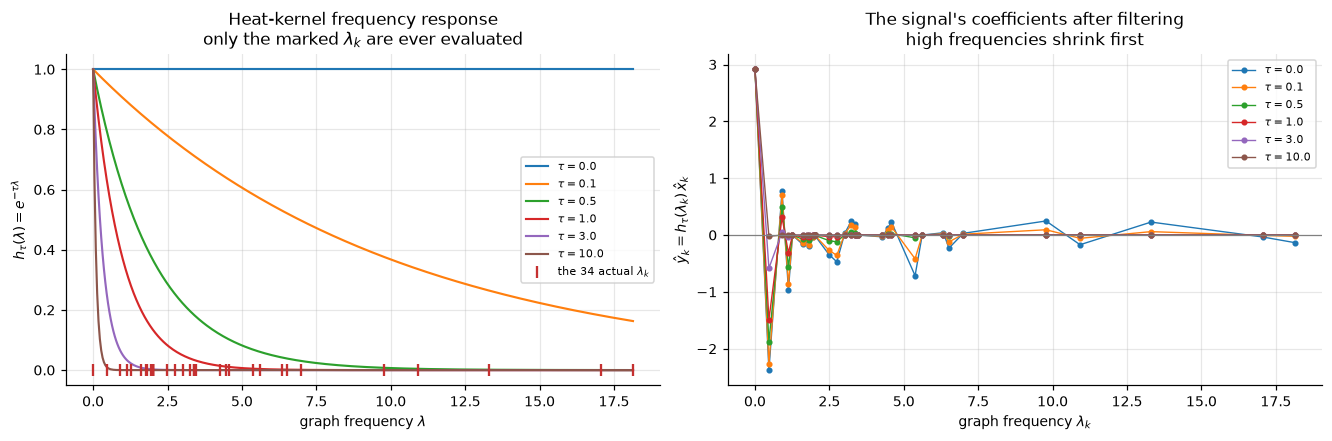

In [21]:
def spectral_filter(signal, response):
    # y = U h(Lambda) U^T x -- multiply each coefficient by h evaluated at its own eigenvalue.
    return igft(response(lam) * gft(signal))

def heat(tau):
    return lambda lmbda: np.exp(-tau * lmbda)

taus = [0.0, 0.1, 0.5, 1.0, 3.0, 10.0]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.9))
grid = np.linspace(0, lam[-1], 400)
for tau in taus:
    axes[0].plot(grid, np.exp(-tau * grid), lw=1.4, label=fr"$\tau = {tau}$")
axes[0].scatter(lam, np.zeros(N), marker="|", s=60, color=C_RED, zorder=5,
                label="the 34 actual $\\lambda_k$")
axes[0].set_xlabel(r"graph frequency $\lambda$")
axes[0].set_ylabel(r"$h_\tau(\lambda) = e^{-\tau\lambda}$")
axes[0].set_title("Heat-kernel frequency response\nonly the marked $\\lambda_k$ are ever evaluated")
axes[0].legend(fontsize=7.5)

for tau in taus:
    axes[1].plot(lam, np.exp(-tau * lam) * xhat, "o-", ms=3, lw=0.9, label=fr"$\tau = {tau}$")
axes[1].axhline(0, color="gray", lw=0.8)
axes[1].set_xlabel(r"graph frequency $\lambda_k$")
axes[1].set_ylabel(r"$\hat{y}_k = h_\tau(\lambda_k)\,\hat{x}_k$")
axes[1].set_title("The signal's coefficients after filtering\nhigh frequencies shrink first")
axes[1].legend(fontsize=7.5)
plt.show()

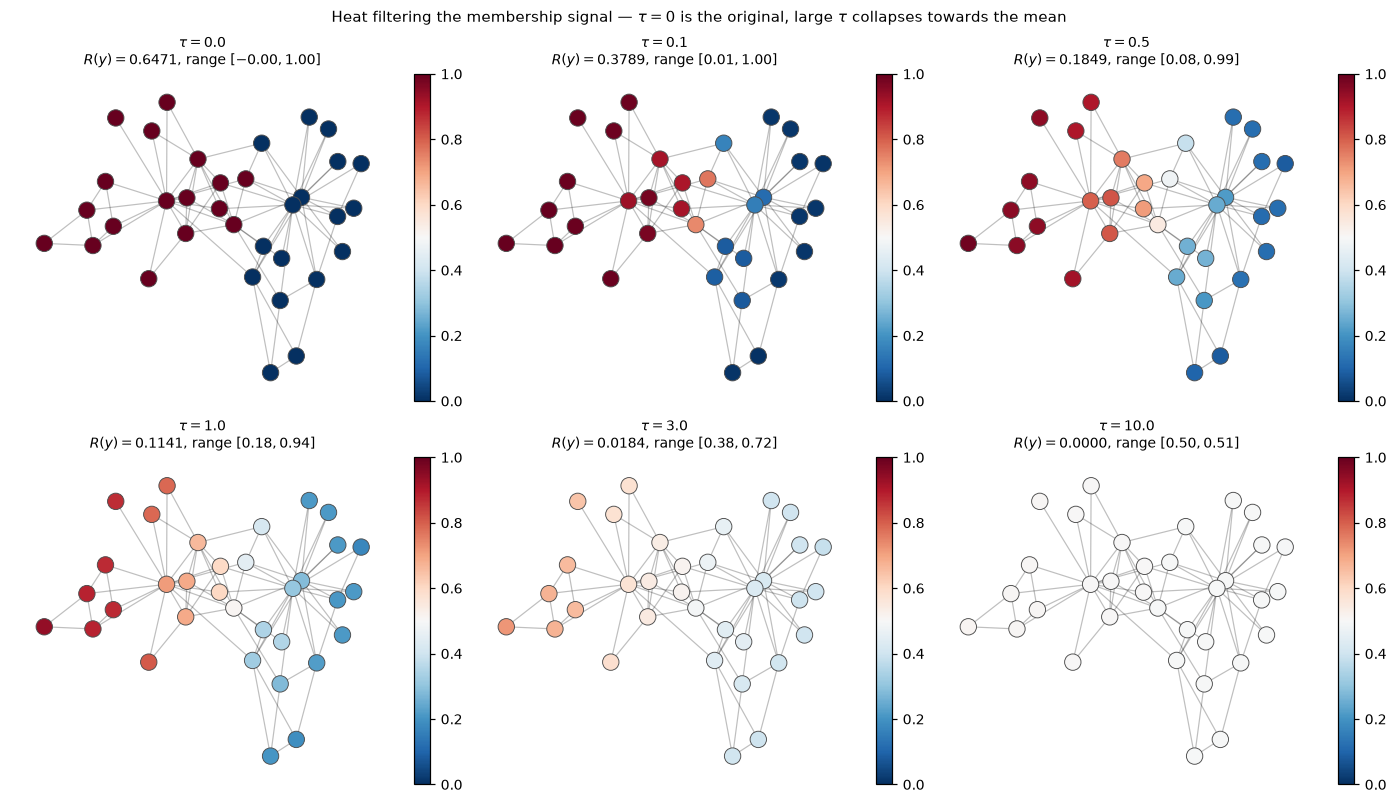

   tau       R(y)     mean              range   agrees with labels
   0.0    0.64706   0.5000    [-0.000, 1.000]              100.0%
   0.1    0.37888   0.5000     [0.005, 1.000]              100.0%
   0.5    0.18492   0.5000     [0.083, 0.985]               97.1%
   1.0    0.11413   0.5000     [0.175, 0.940]               97.1%
   3.0    0.01838   0.5000     [0.383, 0.720]               94.1%
  10.0    0.00003   0.5000     [0.496, 0.509]               94.1%


In [22]:
fig, axes = plt.subplots(2, 3, figsize=(12.6, 7.2))
filtered = {tau: spectral_filter(x, heat(tau)) for tau in taus}
mf = max(np.abs(np.concatenate([v for v in filtered.values()]) - 0.5).max(), 0.5)

for ax, tau in zip(axes.ravel(), taus):
    y = filtered[tau]
    nodes = draw_on_graph(ax, y,
                          f"$\\tau = {tau}$\n$R(y) = {rayleigh(y):.4f}$, "
                          f"range $[{y.min():.2f}, {y.max():.2f}]$",
                          vmin=0.5 - mf, vmax=0.5 + mf)
    fig.colorbar(nodes, ax=ax, fraction=0.045)
fig.suptitle("Heat filtering the membership signal — $\\tau = 0$ is the original, "
             "large $\\tau$ collapses towards the mean", fontsize=10)
plt.show()

print(f"{'tau':>6s} {'R(y)':>10s} {'mean':>8s} {'range':>18s} {'agrees with labels':>20s}")
for tau in taus:
    y = filtered[tau]
    print(f"{tau:6.1f} {rayleigh(y):10.5f} {y.mean():8.4f} "
          f"{'[' + format(y.min(), '.3f') + ', ' + format(y.max(), '.3f') + ']':>18s} "
          f"{np.mean((y > 0.5) == (x > 0.5)):19.1%}")

The mean is identical in every row — $h_\tau(0)=1$ guarantees it — while the range collapses towards
that mean and the Rayleigh quotient falls by four orders of magnitude. At $\tau=10$ every node sits
within $0.01$ of $0.5$: the signal has been almost entirely destroyed, yet the *ordering* of nodes
survives well enough that thresholding still agrees with 94.1% of the labels. Smoothness and
information are different things.

### Gradual attenuation versus a hard cutoff

Both the heat kernel and truncation are low-pass. Comparing them fairly means comparing at **equal
smoothness** rather than at some arbitrary pairing of $\tau$ with $K$ — otherwise we would only be
measuring which one we tuned harder. So for each $K$ we solve for the $\tau$ that produces the same
Rayleigh quotient, then ask which output is closer to the original signal.


In [23]:
def tau_matching_smoothness(target_R, lo=0.0, hi=50.0, iters=200):
    # Bisection on tau: R(y) decreases monotonically as tau grows.
    for _ in range(iters):
        mid = 0.5 * (lo + hi)
        if rayleigh(spectral_filter(x, heat(mid))) > target_R:
            lo = mid
        else:
            hi = mid
    return lo

print(f"{'K':>3s} {'cutoff R(y)':>12s} {'cutoff error':>13s} | "
      f"{'matched tau':>12s} {'heat R(y)':>10s} {'heat error':>11s}")
for K in [2, 3, 5, 10]:
    y_cut = reconstruct(xhat, K)
    tau_m = tau_matching_smoothness(rayleigh(y_cut))
    y_heat = spectral_filter(x, heat(tau_m))
    print(f"{K:3d} {rayleigh(y_cut):12.5f} "
          f"{np.linalg.norm(x - y_cut) / np.linalg.norm(x):13.4f} | "
          f"{tau_m:12.3f} {rayleigh(y_heat):10.5f} "
          f"{np.linalg.norm(x - y_heat) / np.linalg.norm(x):11.4f}")
print()
print("At matched smoothness the heat kernel is closer to the original signal in every row.")

  K  cutoff R(y)  cutoff error |  matched tau  heat R(y)  heat error
  2      0.18692        0.4100 |        0.490    0.18692      0.2932
  3      0.21637        0.3644 |        0.367    0.21637      0.2570
  5      0.27107        0.2779 |        0.225    0.27107      0.2002
 10      0.27797        0.2699 |        0.213    0.27797      0.1940

At matched smoothness the heat kernel is closer to the original signal in every row.


At equal smoothness the gradual filter is consistently closer to the original — at $K=2$, relative
error $0.29$ against $0.41$. The reason is that a brick wall must *throw away* a mode that carries
real signal just because it sits above the cutoff, whereas the heat kernel keeps a shrunken copy of
it. Sharp cutoffs in frequency also produce ringing-like artefacts in the node domain, the graph
analogue of Gibbs phenomenon — visible above as reconstructions that overshoot outside $[0,1]$.

> ⚠️ **Smoothing is not denoising, unless you can show it is.** It is tempting to call the filtered
> signal "denoised". That claim requires three things we do not have here: a **noise model**, a
> **clean target** to compare against, and an **evaluation** showing the filtered version is closer
> to that target than the input. Our signal has no noise — the recorded factions are the
> measurement, not a corrupted version of something else — so there is nothing to remove and no
> target to get closer to. What we have demonstrated is that filtering *changes* the signal in a
> controlled, frequency-selective way. Whether that change is an improvement is a question about an
> application, and it needs an answer before the word "denoising" is used.
>
> Note also what smoothing costs: at $\tau=3$ the sharp boundary between factions is gone, replaced
> by a gradient. If the boundary is the thing you care about — and in community detection it is —
> then smoothing has erased the signal of interest while improving every smoothness metric.

> 📖 **Reference — filters and operator choice.**
> [Ortega, Frossard, Kovačević, Moura & Vandergheynst, *Graph Signal Processing: Overview,
> Challenges and Applications* (2018)](https://arxiv.org/abs/1712.00468). Broader than Shuman et al.
> on how the choice of operator (adjacency, combinatorial or normalised Laplacian) changes the
> frequency axis and therefore what a "low-pass" filter means, and on sampling and recovery — the
> held-out prediction problem that Section 4 deliberately did *not* attempt.


---
## 6. An applied extension: an electrical network

The karate club has a dimensionless signal on a social graph. A power grid gives something
different: a physical network with several *distinct* measured quantities in real units, which lets
us ask a question that cannot arise with a single signal — **are different quantities on the same
network equally smooth?**

**The data.** The IEEE 14-bus test case as distributed with
[MATPOWER](https://matpower.org/docs/ref/matpower5.0/case14.html): 14 buses, 20 branches. We embed
the handful of columns we need directly below, so this notebook needs no download.

**Provenance, and why it matters here.** This case was converted from the IEEE Common Data Format
file `ieee14cdf.txt` (dated 1962, archived at the
[University of Washington power systems test case archive](https://labs.ece.uw.edu/pstca/)). The
values are a **solved benchmark operating case** — one converged power-flow solution for a small
fictitious network used to test algorithms. They are not measurements, not a time series, and not
from any real utility. Nothing here supports a claim about how an actual grid behaves.

**Modelling choices, stated explicitly.**

- **We use the branch list as an unweighted graph.** This is a deliberate simplification and, for
  this domain, a significant one: the physically meaningful operator is the *susceptance-weighted*
  Laplacian $B$ with $B_{ij}=-1/x_{ij}$, which is exactly the DC power-flow operator relating
  injections to voltage angles. Weighted graphs are the subject of a later lesson; until then, read
  the results below as "what the connectivity alone explains", not as power-system physics.
- **Three branches are transformers** (4–7, 4–9, 5–6, with off-nominal tap ratios), so the network
  spans several voltage levels. Voltage magnitude is in per-unit, normalised against each bus's own
  base, which keeps it comparable — but the graph is not electrically homogeneous.
- **The `baseKV` column is all zeros in this file**, an artefact of the CDF conversion. The bus
  names encode the voltage level instead (HV/LV/ZV/TV). Mentioning this is the point: a documented
  benchmark can still contain fields that are unusable, and checking beats assuming.


In [24]:
# IEEE 14-bus case, MATPOWER `case14.m`, columns bus_i, Pd, Qd, Vm, Va.
#   Pd  real power demand      [MW]
#   Qd  reactive power demand  [MVAr]
#   Vm  voltage magnitude      [per unit]
#   Va  voltage angle          [degrees]
BUS = np.array([
    [1,   0.0,   0.0, 1.060,   0.00], [2,  21.7,  12.7, 1.045,  -4.98],
    [3,  94.2,  19.0, 1.010, -12.72], [4,  47.8,  -3.9, 1.019, -10.33],
    [5,   7.6,   1.6, 1.020,  -8.78], [6,  11.2,   7.5, 1.070, -14.22],
    [7,   0.0,   0.0, 1.062, -13.37], [8,   0.0,   0.0, 1.090, -13.36],
    [9,  29.5,  16.6, 1.056, -14.94], [10,  9.0,   5.8, 1.051, -15.10],
    [11,  3.5,   1.8, 1.057, -14.79], [12,  6.1,   1.6, 1.055, -15.07],
    [13, 13.5,   5.8, 1.050, -15.16], [14, 14.9,   5.0, 1.036, -16.04],
])
# Branch list: (from bus, to bus). Branches 4-7, 4-9 and 5-6 are transformers.
BRANCH = [(1, 2), (1, 5), (2, 3), (2, 4), (2, 5), (3, 4), (4, 5), (4, 7), (4, 9), (5, 6),
          (6, 11), (6, 12), (6, 13), (7, 8), (7, 9), (9, 10), (9, 14), (10, 11), (12, 13), (13, 14)]

Gp = nx.Graph()
Gp.add_nodes_from(range(1, 15))
Gp.add_edges_from(BRANCH)

bus_list = sorted(Gp.nodes())
Np = len(bus_list)
Ap = nx.to_numpy_array(Gp, nodelist=bus_list, weight=None)
Lp = np.diag(Ap.sum(axis=1)) - Ap
lam_p, U_p = np.linalg.eigh(Lp)

print(f"buses {Np}, branches {Gp.number_of_edges()}, "
      f"connected {nx.is_connected(Gp)}, self-loops {nx.number_of_selfloops(Gp)}")
print(f"parallel branches: {len(BRANCH) != len(set(map(frozenset, BRANCH)))}")
print(f"lambda_2 = {lam_p[1]:.4f},  lambda_max = {lam_p[-1]:.4f}")

buses 14, branches 20, connected True, self-loops 0
parallel branches: False
lambda_2 = 0.4584,  lambda_max = 6.4832


In [25]:
SIGNALS = [("Pd  real demand", 1, "MW"), ("Qd  reactive demand", 2, "MVAr"),
           ("Vm  voltage magnitude", 3, "p.u."), ("Va  voltage angle", 4, "deg")]

# Every signal is mean-centred before comparison: the constant mode carries only the
# overall level, which differs wildly between MW and per-unit volts and would swamp
# any comparison of STRUCTURE. We compare Rayleigh quotients, never raw energies,
# because Dirichlet energy scales with ||x||^2 and these signals have different sizes.
N_NULL_P = 5000
print(f"{'signal':24s}{'unit':>7s}{'R(x)':>9s}{'null mean R':>13s}{'pct <= obs':>12s}"
      f"{'E in k=2..5':>13s}")
grid_results = {}
for name, col, unit in SIGNALS:
    s = BUS[:, col]
    sc = s - s.mean()
    R_obs = (sc @ Lp @ sc) / (sc @ sc)
    nulls = np.empty(N_NULL_P)
    for t in range(N_NULL_P):
        p = rng.permutation(sc)
        nulls[t] = (p @ Lp @ p) / (p @ p)
    sh = U_p.T @ sc
    low = (sh[1:5] ** 2).sum() / (sh ** 2).sum()
    grid_results[name] = (sc, sh, R_obs, np.mean(nulls <= R_obs))
    print(f"{name:24s}{unit:>7s}{R_obs:9.4f}{nulls.mean():13.4f}"
          f"{100 * np.mean(nulls <= R_obs):11.1f}%{100 * low:12.1f}%")

signal                     unit     R(x)  null mean R  pct <= obs  E in k=2..5
Pd  real demand              MW   1.7503       3.0843        6.0%        39.4%
Qd  reactive demand        MVAr   3.8667       3.0697       85.6%        22.9%
Vm  voltage magnitude      p.u.   2.0706       3.0738        7.2%        62.8%
Va  voltage angle           deg   1.0081       3.0840        0.1%        76.8%


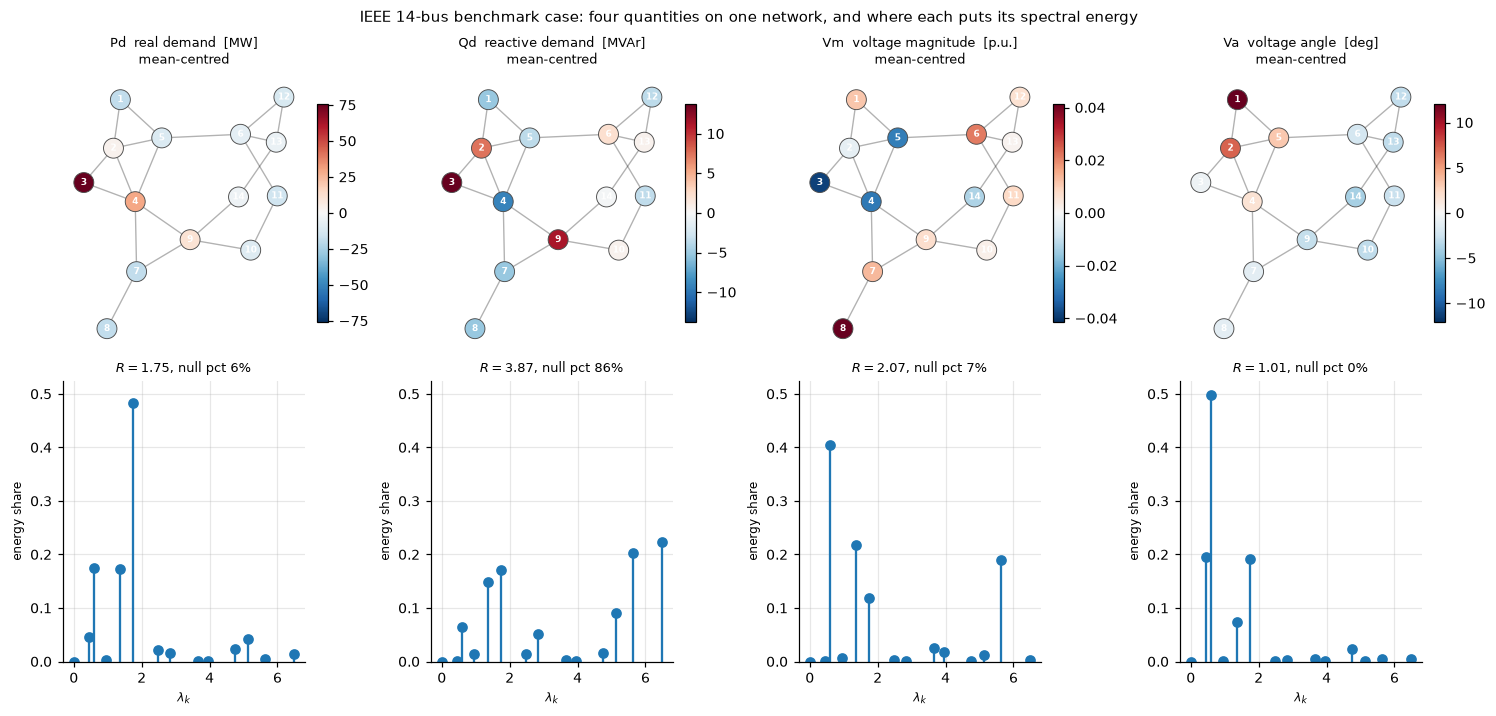

In [26]:
fig, axes = plt.subplots(2, 4, figsize=(13.5, 6.4))
pos_p = nx.spring_layout(Gp, seed=SEED, weight=None)

for col_i, (name, col, unit) in enumerate(SIGNALS):
    sc, sh, R_obs, pct = grid_results[name]
    ax = axes[0, col_i]
    m_ = np.abs(sc).max()
    nx.draw_networkx_edges(Gp, pos_p, ax=ax, alpha=0.3, width=0.9)
    nodes = nx.draw_networkx_nodes(Gp, pos_p, ax=ax, nodelist=bus_list, node_color=sc,
                                   cmap="RdBu_r", vmin=-m_, vmax=m_, node_size=170,
                                   edgecolors="0.3", linewidths=0.6)
    nx.draw_networkx_labels(Gp, pos_p, ax=ax, font_size=6, font_color="white",
                            font_weight="bold")
    ax.set_title(f"{name}  [{unit}]\nmean-centred", fontsize=8.5)
    ax.set_axis_off(); ax.grid(False)
    fig.colorbar(nodes, ax=ax, fraction=0.045)

    ax2 = axes[1, col_i]
    ax2.stem(lam_p, sh ** 2 / (sh ** 2).sum(), basefmt=" ")
    ax2.set_xlabel(r"$\lambda_k$", fontsize=8)
    ax2.set_ylabel("energy share", fontsize=8)
    ax2.set_title(f"$R={R_obs:.2f}$, null pct {100 * pct:.0f}%", fontsize=8.5)
    ax2.set_ylim(0, 1.05 * max((h ** 2 / (h ** 2).sum()).max()
                               for _, h, _, _ in grid_results.values()))
fig.suptitle("IEEE 14-bus benchmark case: four quantities on one network, "
             "and where each puts its spectral energy", fontsize=10)
plt.show()

**The four quantities are emphatically not equally smooth**, even though they live on the same
buses and the same branches.

- **Voltage angle** is the smoothest by a wide margin — smoother than $99.9\%$ of random
  reassignments, with 77% of its energy in the four lowest non-constant modes. That is not a
  coincidence: in the DC power-flow approximation the angles satisfy $B\theta = P$ with $B$ a
  weighted Laplacian, so angle is, by construction, a smooth function of a Laplacian-like operator
  on this network. The spectral analysis is recovering a shadow of the physics — and it is the
  *weighted* operator that makes the statement exact, which is precisely why the weighting
  simplification above was flagged rather than hidden.
- **Real demand and voltage magnitude** are moderately smooth (6th to 7th percentile of the
  null), but for different reasons: demand is dominated by one large load at bus 3 (94.2 MW), which
  is a localised feature, not a smooth one.
- **Reactive demand is not smooth at all.** About 86% of random reassignments are *smoother* than
  the real thing. Its spectral energy sits at high frequency, meaning adjacent buses routinely have
  very different reactive loads.

If we had examined only the angle and concluded "grid quantities are low-frequency signals, so
low-pass filtering is appropriate", reactive demand would have been quietly mangled. The null model
is what makes the difference visible rather than assumed.

> ⚠️ **Do not over-read this.** The graph is unweighted while the physics is weighted; the values
> are one benchmark operating point, not measurements; and the smoothness of a solved case reflects
> the equations that produced it as much as any network property. What this extension demonstrates
> is methodological: **test each signal, do not generalise across quantities.**


---
## Recap, interpretation questions, and checks

### What the GFT told us

| Quantity | Meaning | Value here |
|---|---|---|
| $\widehat{x}_k = u_k^\top x$ | overlap of the signal with graph mode $k$ | 34 numbers, one per frequency |
| $\widehat{x}_1 = \sqrt{N}\bar{x}$ | the constant mode carries the mean | $2.915$, exactly $\sqrt{34}\cdot 0.5$ |
| $\|x\|^2 = \sum_k\|\widehat{x}_k\|^2$ | Parseval: the basis change preserves energy | $17.0$ both ways |
| $x^\top Lx = \sum_k\lambda_k\|\widehat{x}_k\|^2$ | Dirichlet energy, resolved by frequency | $11.0$, matching the edge form |
| $x^\top Lx$ for a 0/1 signal | **exactly** the number of edges between clubs | $11$ of $78$ |
| permutation null | is the signal aligned with the structure? | below the minimum of 5000 shuffles |
| energy in $u_2$ (centred) | overlap with the graph's principal bottleneck | $66.4\%$ |
| $\|x-x^{(K)}\|^2 = \sum_{k>K}\|\widehat{x}_k\|^2$ | truncation error is the discarded energy | verified to $10^{-15}$ |
| $y = Uh(\Lambda)U^\top x$ | filtering = pointwise scaling per frequency | heat kernel preserves the mean exactly |

### The applied takeaway

The question was *how well does the network's structure explain the observed membership?* The answer
has three parts, and only the first is usually reported.

1. **Strongly, by the natural measure.** Membership disagrees across 11 of 78 edges where a random
   reassignment would disagree across about 40, and the observed value lies below the minimum of
   5000 shuffles. Two-thirds of the non-constant energy sits in a single mode.
2. **But "explains" means alignment, not mechanism.** The same statistic would appear whether
   friendships drove factional choice or pre-existing factions shaped who socialised with whom. The
   GFT measures agreement between a signal and a structure; it cannot order them in time or assign
   a cause.
3. **And the representation is compact only for some purposes.** Two coefficients capture the
   faction structure far better than any two node values, yet the signal is *exactly* representable
   by 17 node values and never exactly by fewer than 34 graph modes. Compactness is relative to what
   you are trying to preserve.

The transferable habits: state what the signal is and what units it carries; separate the constant
mode from the structure; compare energies only after normalising; calibrate every smoothness claim
against a null model; and check each quantity separately rather than assuming that signals sharing
a network share its frequency profile.

### Check your understanding

<details>
<summary><b>1.</b> Your colleague computes the GFT of a sensor reading, finds $\widehat{x}_1$ is by
far the largest coefficient, and concludes the signal is very smooth on the network. What is the
problem?</summary>

$\widehat{x}_1 = \sqrt{N}\bar{x}$ is the mean, and almost any signal with a non-zero average will
have a dominant first coefficient — a constant signal of $1000$ would have essentially all of its
energy there while saying nothing about the network. The constant mode contributes exactly zero to
the Dirichlet energy, since $\lambda_1 = 0$, so it carries no smoothness information at all. Centre
the signal and look at the distribution of the remaining coefficients, as Section 3 does; there the
Fiedler mode carrying 66% of the non-constant energy is a genuine structural statement.
</details>

<details>
<summary><b>2.</b> Two signals on the same graph have Dirichlet energies $11$ and $2\,400$. Is the
second rougher?</summary>

Unknown from those numbers. Dirichlet energy scales as $\|x\|^2$, so a signal measured in watts
rather than kilowatts gains a factor of $10^6$ with no change in shape. Compare Rayleigh quotients
$\mathcal{R}(x) = x^\top Lx / x^\top x$ instead, and state whether you centred first. Section 6 does
exactly this to compare MW against per-unit volts against degrees, and adds a permutation null so
that each $\mathcal{R}$ has a scale of its own.
</details>

<details>
<summary><b>3.</b> Why can you not order the nodes sensibly and use an ordinary FFT?</summary>

Because the FFT assumes its samples sit on a path — sample $i$ adjacent to $i\pm1$ — and a graph
provides no such ordering. Section 2 demonstrates the consequence: relabelling the nodes leaves the
GFT magnitudes unchanged to machine precision while changing the FFT magnitudes by $4.5$. An FFT
would not merely lose the graph structure, it would impose a fictitious one and report its
properties. The "sensible ordering" in the question is the trap: any ordering you choose is a
modelling assumption about adjacency that the data does not support.
</details>

<details>
<summary><b>4.</b> You low-pass filter a network signal, the result looks cleaner, and you write
that you denoised it. What is missing?</summary>

A noise model, a clean target, and an evaluation. Smoothing always makes a signal smoother — that is
its definition, not evidence — so "looks cleaner" is circular. To claim denoising you need to say
what the noise is, what the uncorrupted signal would be, and show the filtered version is measurably
closer to it than the input was, on data not used to tune the filter. Section 5 shows the cost of
skipping this: at $\tau=3$ every smoothness metric improves while the faction boundary, the thing of
interest, is erased.
</details>

<details>
<summary><b>5.</b> A truncated reconstruction gives $x^{(5)}_i = 0.81$ for node $i$. Can you report
that as an 81% probability that node $i$ belongs to the first group?</summary>

No. $x^{(5)}$ is an orthogonal projection of a binary vector onto a 5-dimensional subspace, with no
probabilistic model anywhere in its construction and no calibration against outcomes. The clearest
evidence is that other entries fall outside $[0,1]$, which no probability can. It is a continuous
approximation to a binary value; if you need calibrated probabilities you need a model that produces
them and a held-out set to check them on.
</details>

<details>
<summary><b>6.</b> The graph basis beat the node basis at every small $K$ but lost at $K=17$.
Does that mean the GFT failed?</summary>

No — it means "better basis" is not a property a basis has on its own. The signal is 17-sparse in the
node domain by construction (17 ones), so 17 node values reproduce it exactly, while a hard step
needs all 34 smooth modes. The graph basis wins overwhelmingly when the goal is a *faithful
few-number summary of shape* ($0.41$ against $0.94$ relative error at $K=2$) and its early
coefficients are interpretable, which node entries are not. Report the crossover rather than the
half of the curve that flatters the method.
</details>

<details>
<summary><b>7.</b> Every quantity in the power-grid extension lives on the same 14 buses and the
same 20 branches. Why do they have such different spectra?</summary>

Because the graph supplies the basis, not the signal. The eigenvectors and eigenvalues are identical
for all four quantities — that part is Lesson 1 and depends only on the branches — while the
coefficients $\widehat{x}_k$ depend entirely on what was measured. Voltage angle is smooth because
it approximately solves a Laplacian system on this network; reactive demand is rougher than 86% of
random reassignments because reactive loads are a local property of each bus. Sharing a domain does
not make two signals share a frequency profile, which is why each needs testing separately.
</details>

### Correctness checks

Every identity claimed above, verified rather than trusted.


In [27]:
tol = 1e-9
checks = []

def check(name, ok, detail=""):
    checks.append((name, bool(ok), detail))

# --- the operator and its eigendecomposition ---------------------------------
check("A symmetric, 0/1, zero diagonal",
      np.allclose(A, A.T) and set(np.unique(A)) <= {0.0, 1.0} and np.allclose(np.diag(A), 0))
check("L = D - A, symmetric", np.allclose(L, np.diag(d) - A) and np.allclose(L, L.T))
check("L @ 1 == 0", np.abs(L @ np.ones(N)).max() < tol,
      f"max |L @ 1| = {np.abs(L @ np.ones(N)).max():.2e}")
check("eigenvalues ascending and non-negative",
      np.all(np.diff(lam) >= -tol) and lam.min() > -tol, f"min lambda = {lam.min():.2e}")

orth = np.abs(U.T @ U - np.eye(N)).max()
check("U^T U == I (orthonormality)", orth < 1e-9, f"max |error| = {orth:.2e}")
recon = np.abs(U @ np.diag(lam) @ U.T - L).max()
check("L == U diag(lambda) U^T", recon < 1e-9, f"max |error| = {recon:.2e}")
eig_res = max(np.abs(L @ U[:, k] - lam[k] * U[:, k]).max() for k in range(N))
check("L u_k == lambda_k u_k for every k", eig_res < 1e-9, f"max residual = {eig_res:.2e}")
check("exactly one zero eigenvalue == one component",
      int(np.sum(np.abs(lam) < 1e-8)) == nx.number_connected_components(G))

# --- the transform ------------------------------------------------------------
check("gft is the matrix product U^T x", np.allclose(gft(x), U.T @ x))
inv_err = np.abs(igft(gft(x)) - x).max()
check("igft(gft(x)) == x (exact inversion)", inv_err < 1e-9, f"max |error| = {inv_err:.2e}")
check("xhat_k == u_k^T x for every k",
      max(abs(xhat[k] - U[:, k] @ x) for k in range(N)) < tol)
check("x == sum_k xhat_k u_k (explicit resynthesis)",
      np.allclose(x, sum(xhat[k] * U[:, k] for k in range(N))))
check("constant mode carries the mean: |xhat_1| == sqrt(N) * xbar",
      np.isclose(abs(xhat[0]), np.sqrt(N) * x.mean()),
      f"{abs(xhat[0]):.6f} vs {np.sqrt(N) * x.mean():.6f}")

# --- Parseval and Dirichlet ---------------------------------------------------
check("Parseval: ||x||^2 == sum |xhat_k|^2", np.isclose(x @ x, (xhat ** 2).sum()),
      f"{x @ x:.8f} vs {(xhat ** 2).sum():.8f}")
check("Parseval holds for a random test vector too",
      np.isclose((q := rng.standard_normal(N)) @ q, (gft(q) ** 2).sum()))
check("Dirichlet: matrix form == edge form",
      np.isclose(x @ L @ x, dirichlet_edges(x)))
check("Dirichlet: matrix form == spectral form sum lam_k |xhat_k|^2",
      np.isclose(x @ L @ x, (lam * xhat ** 2).sum()),
      f"{x @ L @ x:.8f} vs {(lam * xhat ** 2).sum():.8f}")
check("Dirichlet of a 0/1 signal == number of crossing edges",
      np.isclose(x @ L @ x, len(cut_edges)), f"{x @ L @ x:.1f} == {len(cut_edges)}")
check("constant mode contributes zero Dirichlet energy",
      np.isclose(lam[0] * xhat[0] ** 2, 0.0))
check("Rayleigh quotient invariant to rescaling",
      np.isclose(rayleigh(x), rayleigh(13.7 * x)))

# --- reconstruction -----------------------------------------------------------
tail_ok = all(np.isclose(np.linalg.norm(x - reconstruct(xhat, K)) ** 2, (xhat[K:] ** 2).sum())
              for K in range(1, N + 1))
check("||x - x^(K)||^2 == sum_{k>K} |xhat_k|^2 for every K", tail_ok)
check("x^(N) reproduces x exactly",
      np.abs(reconstruct(xhat, N) - x).max() < 1e-9)
check("reconstruction error decreases monotonically in K",
      np.all(np.diff(err_gft) <= 1e-12))

# --- filtering ----------------------------------------------------------------
check("heat filter with tau = 0 is the identity",
      np.allclose(spectral_filter(x, heat(0.0)), x))
check("heat filter preserves the mean exactly (h(0) = 1)",
      all(np.isclose(spectral_filter(x, heat(t)).mean(), x.mean()) for t in taus))
check("heat filter is smoothing: R(y) decreases as tau grows",
      np.all(np.diff([rayleigh(spectral_filter(x, heat(t))) for t in sorted(taus)]) < 0))
check("filtering equals coefficient-wise multiplication",
      np.allclose(gft(spectral_filter(x, heat(1.3))), np.exp(-1.3 * lam) * xhat))

# --- null model ---------------------------------------------------------------
check("permutation null preserves the multiset of signal values",
      np.array_equal(np.sort(rng.permutation(x)), np.sort(x)))
check("null simulation matches the analytic expectation",
      abs(null_energy.mean() - expected) < 0.5,
      f"{null_energy.mean():.2f} vs {expected:.2f}")
check("observed energy below the whole null distribution",
      x @ L @ x < null_energy.min(), f"{x @ L @ x:.0f} < {null_energy.min():.0f}")

# --- the power-grid extension -------------------------------------------------
check("case14 graph: 14 buses, 20 branches, connected, simple",
      Np == 14 and Gp.number_of_edges() == 20 and nx.is_connected(Gp)
      and nx.number_of_selfloops(Gp) == 0)
check("case14 eigenpair residual",
      max(np.abs(Lp @ U_p[:, k] - lam_p[k] * U_p[:, k]).max() for k in range(Np)) < 1e-9)
check("case14 Parseval on every signal",
      all(np.isclose(sc @ sc, ((U_p.T @ sc) ** 2).sum())
          for sc, _, _, _ in grid_results.values()))
check("the four grid signals are NOT equally smooth",
      max(r[2] for r in grid_results.values()) > 2 * min(r[2] for r in grid_results.values()),
      f"R ranges {min(r[2] for r in grid_results.values()):.3f} to "
      f"{max(r[2] for r in grid_results.values()):.3f}")

# --- report -------------------------------------------------------------------
width = max(len(nm) for nm, _, _ in checks)
for nm, ok, detail in checks:
    print(f"{'PASS' if ok else 'FAIL'}  {nm:<{width}}  {detail}")

failed = [nm for nm, ok, _ in checks if not ok]
assert not failed, f"failed checks: {failed}"
print(f"\nAll {len(checks)} checks passed.")

PASS  A symmetric, 0/1, zero diagonal                               
PASS  L = D - A, symmetric                                          
PASS  L @ 1 == 0                                                    max |L @ 1| = 0.00e+00
PASS  eigenvalues ascending and non-negative                        min lambda = 2.49e-16
PASS  U^T U == I (orthonormality)                                   max |error| = 1.89e-15
PASS  L == U diag(lambda) U^T                                       max |error| = 2.49e-14
PASS  L u_k == lambda_k u_k for every k                             max residual = 1.60e-14
PASS  exactly one zero eigenvalue == one component                  
PASS  gft is the matrix product U^T x                               
PASS  igft(gft(x)) == x (exact inversion)                           max |error| = 2.44e-15
PASS  xhat_k == u_k^T x for every k                                 
PASS  x == sum_k xhat_k u_k (explicit resynthesis)                  
PASS  constant mode carries the mean: |x

---
## Where to go next

We have put one static number on each node. The natural extensions each relax one of those words.

- **Many numbers per node** — a node-by-time matrix, transformed with this same fixed basis column
  by column, giving a graph-frequency axis and a temporal-frequency axis at once.
- **Weighted edges** — replacing $A$ with a weight matrix $W$, which changes the operator and
  therefore the entire frequency axis. Section 6 flagged exactly where this matters: the
  susceptance-weighted Laplacian, not the unweighted one, is the operator the power-flow equations
  actually use.
- **Signals on edges rather than nodes** — flows, which need oriented incidence operators and a
  notion of conservation, and for which "smooth" means something different again.
- **Sampling and recovery** — the held-out prediction problem this notebook deliberately avoided:
  observe a signal at a subset of nodes and estimate the rest, which requires a proper train/test
  split and a baseline to be meaningful.

### References collected

- **[Shuman, Narang, Frossard, Ortega & Vandergheynst, *The Emerging Field of Signal Processing on
  Graphs* (2013)](https://arxiv.org/abs/1211.0053)** — the primary foundation for this lesson.
  Sections II–III define the GFT, the graph-frequency interpretation of $\lambda_k$, and spectral
  filtering exactly as used here.
- **[Ortega, Frossard, Kovačević, Moura & Vandergheynst, *Graph Signal Processing: Overview,
  Challenges and Applications* (2018)](https://arxiv.org/abs/1712.00468)** — broader coverage of
  operator choice, sampling and recovery, and applications; read it for why the choice between $A$,
  $L$ and $L_{\mathrm{sym}}$ changes what "low-pass" means.
- **[`networkx.karate_club_graph()`](https://networkx.org/documentation/stable/reference/generated/networkx.generators.social.karate_club_graph.html)**
  — the `club` attribute used as our signal, the interaction-count weights we discarded, and the
  citation to Zachary (1977).
- **[MATPOWER IEEE 14-bus case](https://matpower.org/docs/ref/matpower5.0/case14.html)** — the bus
  and branch field definitions for the embedded benchmark data, and the note that it was converted
  from the 1962 IEEE Common Data Format file.

> **A note on what is demonstrated where.** The identities in this notebook — Parseval, the two
> forms of the Dirichlet energy, the truncation-error formula, the heat-kernel response — are
> standard results, stated and developed in Shuman et al. and Ortega et al. The specific analyses
> here are **exercises built for this lesson**: the karate-club membership GFT, the permutation
> null, the graph-versus-node basis comparison, the matched-smoothness filter comparison, and the
> four-quantity IEEE 14-bus comparison are not results reported in those papers. Cite the papers for
> the theory and this notebook for nothing at all.
